# N4 · Experimentos de observaciones múltiples

Un **experimento** es una asimilación de todas las observaciones a la vez, evaluada en una celda del dominio: un (dataset, hora, miembro verdad, celda) y un esquema. Las definiciones son las de N3. El valor central se calcula sobre las sumas de los 12 miembros verdad y las cuatro horas: $\mathrm{RMSE} = \sqrt{\sum \mathrm{SSE}/\sum N}$, con $\mathrm{SSE} = N \cdot \mathrm{RMSE}^2$ por (miembro, hora, dominio), y lo mismo para el CRPS. La banda es ±1 desviación estándar del mismo estadístico entre los 12 miembros verdad, cada uno con sus cuatro horas.

Sección 0: el postprocesado, de las corridas multi-obs REF a los intermedios. Las celdas de análisis calculan los números; las de figura solo dibujan.

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import nbcommon as nb

REBUILD = False           # True: rehace los intermedios desde las corridas (horas: ver la sección 0)
SHOW = "es"
# Umbrales de los gráficos por bin, los de N3
N_MIN_BIN = 200
N_MIN_TRUTH = 20

nb.set_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)

In [39]:
# Etiquetas propias de este notebook; el vocabulario común está en nb.VOCAB.
LABELS = {
    "es": {
        "pos_mean": "desviación media positiva [dBZ]", "neg_mean": "desviación media negativa [dBZ]",
        "namelist": "namelist", "truth_member": "miembro verdad", "not_selected": "no elegido",
        "truth_mean": "media de la verdad", "lon": "longitud [grados]", "height": "altura [km]",
        "norm_innov": "innovación normalizada", "share": "fracción de los experimentos",
        "single_t1": "observación única, TEnKF-T1", "clear_reached": "aire claro alcanzado",
        "ratio_a": "dispersión / RMSE del posterior", "contr_spread": "dispersión posterior / prior",
        "contr_rmse": "RMSE posterior / prior",
    },
    "en": {
        "pos_mean": "mean positive departure [dBZ]", "neg_mean": "mean negative departure [dBZ]",
        "namelist": "namelist", "truth_member": "truth member", "not_selected": "not selected",
        "truth_mean": "truth mean", "lon": "longitude [degrees]", "height": "height [km]",
        "norm_innov": "normalized innovation", "share": "share of experiments",
        "single_t1": "single observation, TEnKF-T1", "clear_reached": "reached clear air",
        "ratio_a": "spread / RMSE of the posterior", "contr_spread": "posterior / prior spread",
        "contr_rmse": "posterior / prior RMSE",
    },
}
for _l in nb.LANGS:
    LABELS[_l]["n_active"] = f"{nb.VOCAB[_l]['n_echo']}, {nb.VOCAB[_l]['n_echo_sym']}"
assert set(LABELS["es"]) == set(LABELS["en"])

## 0 · Postprocesado

Lee las doce corridas multi-obs REF (A, B, C × 18–21 UTC; 12 miembros verdad × 6 esquemas + `ref`) y los subsets, y escribe los intermedios en `data/derived/N4/`. Cada pasada tiene su control `verify`. Los intermedios: `N4_runs`, `N4_nan_cells`, `N4_masks`, `N4_ref_skill`, `N4_scalars`, `N4_sums_spatial_A20.npz`, `N4_sums_pred`, `N4_innov_*`, `N4_state_prior`, `N4_state_spread`, `N4_spread_check`, `N4_state_crps` (el CRPS del prior del estado en las celdas alcanzadas) y `N4_crps_check` (el control de ese método con la reflectividad).

Dos pasadas principales. La primera va por dataset y hora: abre el subset una vez y arma las máscaras de cada miembro verdad (celdas alcanzadas, celdas NaN y su vecindario). La segunda va por dataset y miembro verdad, junta sus cuatro horas y calcula las sumas de la reflectividad desde los campos 3D por dominio. `N4_ref_skill.csv` ya guarda, por (dataset, miembro verdad, hora, esquema, dominio), las sumas que piden las definiciones: $N$, $\sum e_f^2$, $\sum e_a^2$, $\sum \mathrm{CRPS}_f$, $\sum \mathrm{CRPS}_a$, las celdas que mejoran y las que empeoran (con la banda de empate `TOL`).

En serie (`PARALLEL = False`): con `spawn` (macOS) los workers no encuentran funciones definidas en el notebook. Reconstruir todo (`REBUILD = True`) abre cada subset varias veces (C: ~10 GB descomprimido) y tarda horas.

In [40]:
import pathlib
import zipfile
from multiprocessing import get_context

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

import nbcommon as nb
from da.metrics import SKILL_TOL_REF, crps_ensemble_sorted

# ═══════════════════════════════════════════════════════════════════════════
# Configuración
# ═══════════════════════════════════════════════════════════════════════════

OUT = pathlib.Path(nb.DERIVED) / "N4"

DATASETS = ("A", "B", "C")
HOURS    = ("18", "19", "20", "21")
LOC      = 2.0
SCHEMES  = tuple(("TEnKF", n) for n in range(1, 6)) + (("AOEI", 1),)
HYDRO    = ("qg", "qr", "qs")

# Banda de empate de la reflectividad, la misma con la que el runner clasificó su skill.
TOL = nb.TOL["obs"]
assert TOL == SKILL_TOL_REF, "la banda de empate no es la del runner"

# Corte de soporte compacto de simple_letkf_wloc: una celda se actualiza si alguna
# observación está a distancia normalizada d² ≤ (2·√(10/3))². Las celdas alcanzadas
# no están guardadas, solo sus conteos; se reconstruyen con este corte y se comparan
# con n_touched_* del runner en verify().
MAXD2 = (2.0 * np.sqrt(10.0 / 3.0)) ** 2

# En el global de C el runner cuenta 23–35 celdas alcanzadas más que la geometría:
# celdas fuera del alcance con hidrometeoros negativos ínfimos (≥ −3e-20) en el prior,
# que la censura por paso pone en 0 sin que la LETKF las toque; su reflectividad no
# cambia. El runner cuenta hasta 4 menos que esas celdas, más con más pasos (en 7 de 48
# casos con T1 y AOEI, en 23 con T5), sin explicar. Se exige solo la cota: entre 0 y
# las celdas con hidrometeoros negativos fuera del alcance.

# Dominios, todos dentro de las celdas alcanzadas y sin las excluidas:
#   alcanzadas  todas las celdas que la LETKF alcanzó
#   tormenta    columnas con máximo de la verdad ≥ STORM_THRESH_DBZ (da.metrics)
#   observadas  las celdas con una observación asimilada
# Excluidas: las celdas del subset con algún miembro NaN, donde calc_ref devolvió
# 0 dBZ sin avisar, y su vecindario, las celdas dentro del corte de una observación
# ubicada en una de ellas. Esa observación se asimiló con un miembro falso a 0 dBZ o,
# si el roto era la verdad, como aire claro falso. N4_masks.csv guarda cuánto pesa.
DOMAINS = ("alcanzadas", "tormenta", "observadas")

# Media y mediana de la skill del runner (float32) contra las de los campos (float64).
RUNNER_SKILL_ATOL = 1e-4          # dBZ
# Reducción del error cuadrático desde los escalares contra desde los campos.
MSE_FORMULA_RTOL = 1e-9

# En serie por defecto: con `spawn` (macOS) los workers no encuentran las funciones
# definidas bajo %run y el Pool se cuelga. PARALLEL usa `fork`, que las hereda.
PARALLEL = False


def pmap(func, jobs, n_workers):
    if not PARALLEL:
        return [func(j) for j in jobs]
    with get_context("fork").Pool(min(n_workers, len(jobs))) as p:
        return p.map(func, jobs)


N_WORKERS_MASKS = 4               # cada uno abre un subset de ~3 GB
N_WORKERS_SKILL = 12

FILES = ("N4_runs.csv", "N4_nan_cells.csv", "N4_masks.csv", "N4_ref_skill.csv",
         "N4_scalars.csv")

def lab(method, ntemp):
    return "AOEI" if method == "AOEI" else f"TEnKF-T{int(ntemp)}"


def tag_of(ds, hh):
    return f"WS_{ds}_multiobs_{hh}00_LOC{LOC}_REF"


def truth_members():
    """Los miembros verdad, leídos de las configs; las doce tienen que coincidir."""
    tms = {tuple(nb.run_config(tag_of(ds, hh))["sweep"]["truth_members"])
           for ds in ("A", "B", "C") for hh in ("18", "19", "20", "21")}
    assert len(tms) == 1, f"las corridas no usan los mismos miembros verdad: {tms}"
    return tms.pop()


TMS = truth_members()


def scheme_file(ds, hh, method, ntemp, tm):
    tag = tag_of(ds, hh)
    f = sorted(nb.run_dir(tag).glob(f"{tag}_multi_obs_{method}_Nt{ntemp:02d}_*_Ne059_tm{tm:02d}.npz"))
    assert len(f) == 1, f"{tag} {method}-T{ntemp} tm{tm:02d}: {len(f)} archivos"
    return f[0]


def ref_file(ds, hh, tm):
    tag = tag_of(ds, hh)
    return nb.run_dir(tag) / f"{tag}_multi_obs_ref_Ne059_tm{tm:02d}.npz"


def within(pos, L, pts):
    """Celdas (nx, ny, nz) a d² ≤ MAXD2 de alguno de los puntos (n, 3) en km."""
    if len(pts) == 0:
        return np.zeros(pos.shape[:3], bool)
    dist, _ = cKDTree(pts / L).query(pos.reshape(-1, 3) / L, k=1,
                                    distance_upper_bound=np.sqrt(MAXD2) * 1.01)
    return (dist ** 2 <= MAXD2).reshape(pos.shape[:3])

In [41]:
# ═══════════════════════════════════════════════════════════════════════════
# Pasada 1: máscaras, por dataset y hora
# ═══════════════════════════════════════════════════════════════════════════

def masks_one(job):
    ds, hh = job
    tag = tag_of(ds, hh)
    cfg = nb.run_config(tag)
    L = float(cfg["sweep"]["loc_x"])
    assert L == cfg["sweep"]["loc_y"] == cfg["sweep"]["loc_z"] == LOC, "localización no isotrópica"
    with np.load(nb.subset_path(hh, ds)) as f:
        assert str(f["dataset_id"]) == ds
        st = f["state_ensemble"]                         # (nx, ny, nz, 60, 8)
        pos = f["pos_km"].astype(np.float32).astype(np.float64)
    shape = st.shape[:3]

    # Censo de NaN del subset: celda, miembros rotos y variables.
    bad_m = ~np.isfinite(st).all(axis=4)                 # (nx, ny, nz, 60)
    bad = bad_m.any(axis=3)
    nan_rows = [dict(dataset=ds, hour=hh, i=i, j=j, k=k,
                     members=",".join(map(str, np.flatnonzero(bad_m[i, j, k]))))
                for i, j, k in zip(*np.nonzero(bad))]
    negq = st[..., [nb.VI[q] for q in HYDRO]] < 0        # (nx, ny, nz, 60, 3)

    rows, packed = [], {}
    for tm in TMS:
        with np.load(ref_file(ds, hh, tm)) as r:
            assert int(r["truth_member"]) == tm and str(r["dataset_id"]) == ds
            ix, iy, iz = r["ix"], r["iy"], r["iz"]
            thx = r["truth_hx_field"]
        reach = within(pos, L, pos[ix, iy, iz])
        on_bad = bad[ix, iy, iz]
        near = within(pos, L, pos[ix[on_bad], iy[on_bad], iz[on_bad]])
        excl = bad | near
        dm = nb.domain_masks(thx, obs_ijk=(ix, iy, iz), storm_thresh=nb.STORM_THRESH_DBZ)
        others = [m for m in range(st.shape[3]) if m != tm]
        negq_out = int((negq[..., others, :].any(axis=(3, 4)) & ~reach).sum())
        touched = {}
        for m, nt in SCHEMES:
            with np.load(scheme_file(ds, hh, m, nt, tm)) as z:
                touched[(m, nt)] = {d: int(z[f"n_touched_{d}"]) for d in ("global", "storm", "obs")}
        row = dict(dataset=ds, hour=hh, tm=tm, n_obs=len(ix), n_cells=int(np.prod(shape)),
                   n_nan_cells=int(bad.sum()), n_obs_on_nan=int(on_bad.sum()),
                   n_negq_outside=negq_out)
        for rd, dn in (("global", "alcanzadas"), ("storm", "tormenta"), ("obs", "observadas")):
            rm = reach & dm[rd]
            row[f"n_reach_{dn}"] = int(rm.sum())
            row[f"n_{dn}"] = int((rm & ~excl).sum())
            row[f"n_nan_{dn}"] = int((rm & bad).sum())
            row[f"frac_near_{dn}"] = float((rm & near).sum() / max(rm.sum(), 1))
            row[f"runner_touched_min_{dn}"] = min(t[rd] for t in touched.values())
            row[f"runner_touched_max_{dn}"] = max(t[rd] for t in touched.values())
        rows.append(row)
        packed[tm] = {k: np.packbits(v.ravel()) for k, v in
                      (("reach", reach), ("excl", excl), ("storm", dm["storm"]), ("obs", dm["obs"]))}
    print(f"  máscaras {ds} {hh}", flush=True)
    return ds, hh, shape, rows, nan_rows, packed

In [42]:
# ═══════════════════════════════════════════════════════════════════════════
# Pasada 2: skill de la reflectividad, por dataset y miembro verdad
# ═══════════════════════════════════════════════════════════════════════════

SUM_COLS = ("sum_err2_f", "sum_err2_a", "sum_crps_f", "sum_crps_a", "sum_var_f", "sum_var_a")


def cell_stats(s, ef, ea, cf, ca, sf, sa):
    """Estadísticos de un conjunto de celdas. s = |err prior| − |err posterior|.

    median_changed es la mediana sobre las celdas fuera de la banda de empate: entre las
    alcanzadas, las que quedan en el piso antes y después son el 36–61 % y llevan la
    mediana de todas a cero por construcción.
    """
    n = s.size
    ch = s[np.abs(s) > TOL]
    return dict(n=n, n_improved=int((s > TOL).sum()), n_degraded=int((s < -TOL).sum()),
                n_tie=int((np.abs(s) <= TOL).sum()),
                mean=float(s.mean()) if n else np.nan,
                median=float(np.median(s)) if n else np.nan,
                median_changed=float(np.median(ch)) if ch.size else np.nan,
                sum_err2_f=float((ef ** 2).sum()), sum_err2_a=float((ea ** 2).sum()),
                sum_crps_f=float(cf.sum()), sum_crps_a=float(ca.sum()),
                sum_var_f=float((sf ** 2).sum()), sum_var_a=float((sa ** 2).sum()))


def skill_one(job):
    ds, tm, shapes, packed = job
    rows, scal, chk = [], [], []
    pooled = {(m, nt, dn): [] for m, nt in SCHEMES for dn in DOMAINS}
    for hh in HOURS:
        P = {k: np.unpackbits(v, count=int(np.prod(shapes[hh]))).reshape(shapes[hh]).astype(bool)
             for k, v in packed[(ds, hh, tm)].items()}
        valid = P["reach"] & ~P["excl"]
        dmask = {"alcanzadas": valid, "tormenta": valid & P["storm"], "observadas": valid & P["obs"]}
        raw = {"global": P["reach"], "storm": P["reach"] & P["storm"], "obs": P["reach"] & P["obs"]}
        prior0 = None
        for m, nt in SCHEMES:
            with np.load(scheme_file(ds, hh, m, nt, tm), allow_pickle=True) as z:
                assert str(z["method"]) == m and int(z["ntemp"]) == nt and int(z["truth_member"]) == tm
                F = {k: z[k].astype(np.float64) for k in
                     ("err_hxf_field", "residual_field", "crps_f_ref_field", "crps_a_ref_field",
                      "spread_f_ref_field", "spread_a_ref_field")}
                sc = {k: z[k].item() for k in z.files
                      if z[k].ndim == 0 and z[k].dtype.kind in "biuf"}
            # el prior es el mismo para los seis esquemas
            pr = (F["err_hxf_field"], F["crps_f_ref_field"], F["spread_f_ref_field"])
            if prior0 is None:
                prior0 = pr
            same_prior = all(np.array_equal(a, b) for a, b in zip(pr, prior0))
            s = np.abs(F["err_hxf_field"]) - np.abs(F["residual_field"])
            ok = np.isfinite(s)
            assert ok.all(), f"{ds} {hh} tm{tm} {m}-T{nt}: skill de reflectividad no finita"
            for dn, msk in dmask.items():
                a = [x[msk] for x in (s, F["err_hxf_field"], F["residual_field"],
                                      F["crps_f_ref_field"], F["crps_a_ref_field"],
                                      F["spread_f_ref_field"], F["spread_a_ref_field"])]
                rows.append(dict(dataset=ds, tm=tm, hour=hh, method=m, ntemp=nt, domain=dn,
                                 **cell_stats(*a)))
                pooled[(m, nt, dn)].append(a[0])       # para la mediana basta la skill
            # La reproducción del runner, sobre la máscara geométrica sin exclusiones.
            c = dict(dataset=ds, hour=hh, tm=tm, method=m, ntemp=nt, same_prior=same_prior)
            for rd, msk in raw.items():
                v = s[msk]
                c[f"d_nskill_{rd}"] = int(sc[f"n_skill_{rd}_ref"]) - v.size
                c[f"d_nimp_{rd}"] = int(sc[f"n_improved_{rd}_ref"]) - int((v > TOL).sum())
                c[f"d_ndeg_{rd}"] = int(sc[f"n_degraded_{rd}_ref"]) - int((v < -TOL).sum())
                c[f"d_mean_{rd}"] = abs(sc[f"skill_mean_{rd}_ref"] - v.mean())
                c[f"d_median_{rd}"] = abs(sc[f"skill_median_{rd}_ref"] - np.median(v))
                # reducción del error cuadrático por celda alcanzada, por las dos vías
                num = (sc[f"n_rmse_f_{rd}_ref"] * sc[f"rmse_f_{rd}_ref"] ** 2
                       - sc[f"n_rmse_a_{rd}_ref"] * sc[f"rmse_a_{rd}_ref"] ** 2)
                fld = (F["err_hxf_field"][msk] ** 2 - F["residual_field"][msk] ** 2).sum()
                c[f"mse_rel_{rd}"] = abs(num - fld) / abs(fld)
            chk.append(c)
            # los escalares ya traen ntemp y truth_member; method es texto y no entra en sc
            scal.append({"dataset": ds, "hour": hh, "tm": tm, "method": m, **sc})
    # Las cuatro horas juntas: conteos, media y mediana desde la skill concatenada; las
    # sumas de error, CRPS y varianza, sumando las filas de cada hora.
    hr = pd.DataFrame(rows)
    for (m, nt, dn), parts in pooled.items():
        s = np.concatenate(parts)
        h = hr[(hr.method == m) & (hr.ntemp == nt) & (hr.domain == dn)]
        r = dict(dataset=ds, tm=tm, hour="all", method=m, ntemp=nt, domain=dn,
                 **cell_stats(s, *(np.zeros(0),) * 6))
        r.update({c: float(h[c].sum()) for c in SUM_COLS})
        rows.append(r)
    print(f"  skill {ds} tm{tm:02d}", flush=True)
    return rows, scal, chk

In [43]:
# ═══════════════════════════════════════════════════════════════════════════
# Construcción y verificación
# ═══════════════════════════════════════════════════════════════════════════

def build():
    OUT.mkdir(parents=True, exist_ok=True)
    runs = []
    for ds in DATASETS:
        for hh in HOURS:
            cfg = nb.run_config(tag_of(ds, hh))
            runs.append(dict(dataset=ds, hour=hh, tag=tag_of(ds, hh), R=nb.obs_error_var(tag_of(ds, hh)),
                             dbz_min=nb.dbz_min_of(tag_of(ds, hh)),
                             clamp=cfg["assimilation"]["clamp_hydro"], loc=cfg["sweep"]["loc_x"],
                             n_files=len(list(nb.run_dir(tag_of(ds, hh)).glob("*.npz"))),
                             storm_thresh=nb.STORM_THRESH_DBZ))
    RUNS = pd.DataFrame(runs)

    jobs = [(ds, hh) for ds in DATASETS for hh in HOURS]
    res = pmap(masks_one, jobs, N_WORKERS_MASKS)
    shapes = {ds: {} for ds in DATASETS}
    packed, mrows, nrows = {}, [], []
    for ds, hh, shape, rows, nan_rows, pk in res:
        shapes[ds][hh] = shape
        mrows += rows
        nrows += nan_rows
        for tm, v in pk.items():
            packed[(ds, hh, tm)] = v
    MASKS, NAN = pd.DataFrame(mrows), pd.DataFrame(nrows)

    jobs = [(ds, tm, shapes[ds], {k: v for k, v in packed.items() if k[0] == ds and k[2] == tm})
            for ds in DATASETS for tm in TMS]
    res = pmap(skill_one, jobs, N_WORKERS_SKILL)
    SK = pd.DataFrame(sum([r[0] for r in res], []))
    SCAL = pd.DataFrame(sum([r[1] for r in res], []))
    CHK = pd.DataFrame(sum([r[2] for r in res], []))

    for name, df in (("N4_runs", RUNS), ("N4_nan_cells", NAN), ("N4_masks", MASKS),
                     ("N4_ref_skill", SK), ("N4_scalars", SCAL)):
        df.to_csv(OUT / f"{name}.csv", index=False)
    return RUNS, NAN, MASKS, SK, SCAL, CHK


def verify(RUNS, NAN, MASKS, SK, SCAL, CHK):
    assert (RUNS.n_files == len(TMS) * (len(SCHEMES) + 1)).all(), "faltan archivos"
    for c in ("R", "dbz_min", "clamp", "loc", "storm_thresh"):
        assert RUNS[c].nunique() == 1, f"las corridas no comparten {c}"
    # Celdas alcanzadas: la geometría reproduce al runner. En tormenta y observadas
    # exacto; en el global, salvo las celdas de hidrometeoros negativos fuera del alcance.
    for dn in ("tormenta", "observadas"):
        assert (MASKS[f"runner_touched_min_{dn}"] == MASKS[f"n_reach_{dn}"]).all() and \
            (MASKS[f"runner_touched_max_{dn}"] == MASKS[f"n_reach_{dn}"]).all(), \
            f"celdas alcanzadas en {dn} no reproducen al runner"
    dmax = MASKS.runner_touched_max_alcanzadas - MASKS.n_reach_alcanzadas
    dmin = MASKS.runner_touched_min_alcanzadas - MASKS.n_reach_alcanzadas
    assert (dmin >= 0).all() and (dmax <= MASKS.n_negq_outside).all(), \
        "celdas alcanzadas de más en el global que los hidrometeoros negativos no explican"
    assert (MASKS.n_obs_on_nan <= MASKS.n_nan_cells).all()
    # El censo del subset contra los escalares de estado del runner: descartó
    # exactamente las celdas NaN, en el prior y en el análisis.
    sc = SCAL.merge(MASKS[["dataset", "hour", "tm", "n_nan_cells", "n_cells"]],
                    on=["dataset", "hour", "tm"])
    for v in nb.VARS:
        for side in ("f", "a"):
            assert (sc.n_cells - sc[f"n_rmse_{side}_global_{v}"] == sc.n_nan_cells).all(), \
                f"los escalares de {v} no descartan justo las celdas NaN"
    assert (sc.n_rmse_f_global_ref == sc.n_cells).all(), "la reflectividad sí descartó celdas"

    # La skill del runner, reproducida desde los campos sobre la máscara geométrica.
    assert CHK.same_prior.all(), "el prior difiere entre esquemas"
    for rd in ("global", "storm", "obs"):
        assert (CHK[f"d_nimp_{rd}"] == 0).all() and (CHK[f"d_ndeg_{rd}"] == 0).all(), \
            f"conteos de mejora/empeora del runner en {rd} no reproducidos"
        assert (CHK[f"d_mean_{rd}"] <= RUNNER_SKILL_ATOL).all() and \
            (CHK[f"d_median_{rd}"] <= RUNNER_SKILL_ATOL).all(), f"skill del runner en {rd}"
        assert (CHK[f"mse_rel_{rd}"] <= MSE_FORMULA_RTOL).all(), \
            f"la reducción del error cuadrático desde escalares no da la de los campos en {rd}"
    for rd in ("storm", "obs"):
        assert (CHK[f"d_nskill_{rd}"] == 0).all()
    # en el global, n_skill del runner lleva las celdas de más (empates exactos)
    m = CHK.merge(MASKS[["dataset", "hour", "tm", "n_negq_outside"]], on=["dataset", "hour", "tm"])
    assert ((m.d_nskill_global >= 0) & (m.d_nskill_global <= m.n_negq_outside)).all()

    # Intermedio de skill: completo, particiones que suman, agrupado = suma de horas.
    assert (SK.n_improved + SK.n_degraded + SK.n_tie == SK.n).all()
    assert (SK.median_changed.notna() == (SK.n_improved + SK.n_degraded > 0)).all(), \
        "median_changed indefinida con celdas que cambian, o al revés"
    hrs = SK[SK.hour != "all"].groupby(["dataset", "tm", "method", "ntemp", "domain"])
    allr = SK[SK.hour == "all"].set_index(["dataset", "tm", "method", "ntemp", "domain"])
    for c in ("n", "n_improved", "n_degraded", "n_tie"):
        h = hrs[c].sum()
        assert (h == allr[c].reindex(h.index)).all(), f"el agrupado de {c} no es la suma de las horas"
    assert hrs.size().eq(len(HOURS)).all()
    assert len(allr) == len(DATASETS) * len(TMS) * len(SCHEMES) * len(DOMAINS)
    print(f"verificado: {len(RUNS)} corridas, {len(CHK)} archivos de esquema, "
          f"{len(NAN)} celdas NaN en los subsets")

### 0.3 · Estructura espacial: sumas por celda

A, 20 UTC, como ejemplo declarado: el nivel a 5 km y la fila del corte de N2. En cada celda, sobre los miembros verdad en que la celda está alcanzada y no excluida, las sumas de $e_f^2$, $e_a^2$, $|e_f|$, $|e_a|$ y los conteos de celdas que cambian y que mejoran. Se guardan en `N4_sums_spatial_A20.npz`.

In [44]:
SP_DS, SP_HOUR = "A", "20"
SP_K = 6                          # el nivel a 5.0 km (verificado al construir)
SP_Z_KM = 5.0
SP_J = 180                        # la fila del corte de N2 (J0 en N2)
SP_SCHEMES = (("TEnKF", 1), ("TEnKF", 2))
SP_FILE = "N4_sums_spatial_A20.npz"
SP_SUMS = ("se2_f", "se2_a", "sae_f", "sae_a", "n_change", "n_imp")


def build_spatial():
    tag = tag_of(SP_DS, SP_HOUR)
    L = float(nb.run_config(tag)["sweep"]["loc_x"])
    with np.load(nb.subset_path(SP_HOUR, SP_DS)) as f:
        pos = f["pos_km"].astype(np.float32).astype(np.float64)
        lats, lons = f["lats"].astype(np.float32), f["lons"].astype(np.float32)
    assert np.allclose(pos[..., SP_K, 2], SP_Z_KM, atol=1e-3), f"el nivel {SP_K} no está a {SP_Z_KM} km"
    nan = pd.read_csv(OUT / "N4_nan_cells.csv", dtype={"hour": str})
    nan = nan[(nan.dataset == SP_DS) & (nan.hour == SP_HOUR)]
    bad = np.zeros(pos.shape[:3], bool)
    bad[nan.i, nan.j, nan.k] = True

    sl = {"map": (slice(None), slice(None), SP_K), "sec": (slice(None), SP_J, slice(None))}
    n_valid = {k: 0 for k in sl}
    truth = {k: 0.0 for k in sl}
    acc = {(m, nt, k, q): 0.0 for m, nt in SP_SCHEMES for k in sl for q in SP_SUMS}
    for tm in TMS:
        with np.load(ref_file(SP_DS, SP_HOUR, tm)) as r:
            ix, iy, iz = r["ix"], r["iy"], r["iz"]
            thx = r["truth_hx_field"].astype(np.float64)
        on_bad = bad[ix, iy, iz]
        valid = (within(pos, L, pos[ix, iy, iz]) & ~bad
                 & ~within(pos, L, pos[ix[on_bad], iy[on_bad], iz[on_bad]]))
        for k, ix_ in sl.items():
            n_valid[k] = n_valid[k] + valid[ix_].astype(int)
            truth[k] = truth[k] + thx[ix_]
        for m, nt in SP_SCHEMES:
            with np.load(scheme_file(SP_DS, SP_HOUR, m, nt, tm)) as z:
                ef = np.abs(z["err_hxf_field"].astype(np.float64))
                ea = np.abs(z["residual_field"].astype(np.float64))
            s = ef - ea
            parts = {"se2_f": ef ** 2, "se2_a": ea ** 2, "sae_f": ef, "sae_a": ea,
                     "n_change": (np.abs(s) > TOL).astype(float), "n_imp": (s > TOL).astype(float)}
            for k, ix_ in sl.items():
                v = valid[ix_]
                for q, x in parts.items():
                    acc[(m, nt, k, q)] = acc[(m, nt, k, q)] + np.where(v, x[ix_], 0.0)
    out = dict(dataset=np.str_(SP_DS), hour=np.str_(SP_HOUR), k=np.int32(SP_K), j=np.int32(SP_J),
               z_map_km=np.float32(SP_Z_KM), n_members=np.int32(len(TMS)), lats=lats, lons=lons,
               cut_lat=lats[SP_J, :], cut_lon=lons[SP_J, :],
               z_km=pos[0, SP_J, :, 2].astype(np.float32))
    for k in sl:
        out[f"{k}_n_valid"] = n_valid[k].astype(np.int16)
        out[f"{k}_truth_mean"] = (truth[k] / len(TMS)).astype(np.float32)
        for m, nt in SP_SCHEMES:
            for q in SP_SUMS:
                out[f"{k}_{q}_{lab(m, nt)}"] = np.asarray(acc[(m, nt, k, q)], np.float64)
    np.savez_compressed(OUT / SP_FILE, **out)
    return out


def verify_spatial(sp):
    for k in ("map", "sec"):
        n = sp[f"{k}_n_valid"]
        assert n.min() >= 0 and n.max() <= len(TMS)
        assert np.isfinite(sp[f"{k}_truth_mean"]).all()
        for m, nt in SP_SCHEMES:
            key = lab(m, nt)
            assert ((sp[f"{k}_n_imp_{key}"] <= sp[f"{k}_n_change_{key}"])
                    & (sp[f"{k}_n_change_{key}"] <= n)).all(), f"{k} {key}: conteos inconsistentes"
            assert (sp[f"{k}_se2_f_{key}"][n == 0] == 0).all(), f"{k} {key}: sumas fuera de las celdas válidas"
    print(f"estructura espacial verificada: {SP_DS} {SP_HOUR} UTC, nivel {SP_K}, fila {SP_J}")

### 0.4 · El prior como predictor: sumas por bin y por miembro verdad

Los predictores y los bordes de N3, reconstruidos en cada celda observada válida: $d = y_o -$ media de $H$ del prior ($y_o$ ya censurado en el piso, como el `dep_b` del barrido), la innovación normalizada $|d|/\sqrt{\sigma_f^2 + R}$ y $N_{Z>0}$. Por (dataset, miembro verdad, esquema, predictor, bin), con las cuatro horas juntas, las mismas sumas que N3: `n`, `se2_f`, `se2_a`, `sae_f`, `sae_a`, `scrps_f`, `scrps_a`, `n_change`, `n_imp`. Se guardan en `N4_sums_pred.csv`.

In [45]:
PRED_EDGES = {"dep_b":            np.arange(-30.0, 30.001, 2.0),
              "norm_innov":       np.arange(0.0, 6.001, 0.25),
              "n_active_f_point": np.arange(-0.5, 59.51, 1.0)}
PRED_SCHEMES = (("TEnKF", 1), ("TEnKF", 2))
PRED_FILE = "N4_sums_pred.csv"
PSUMS = ["n", "se2_f", "se2_a", "sae_f", "sae_a", "scrps_f", "scrps_a", "n_change", "n_imp"]


def pred_one(job):
    ds, hh = job
    tag = tag_of(ds, hh)
    L = float(nb.run_config(tag)["sweep"]["loc_x"])
    R = nb.obs_error_var(tag)
    with np.load(nb.subset_path(hh, ds)) as f:
        pos = f["pos_km"].astype(np.float32).astype(np.float64)
    nan = pd.read_csv(OUT / "N4_nan_cells.csv", dtype={"hour": str})
    nan = nan[(nan.dataset == ds) & (nan.hour == hh)]
    bad = np.zeros(pos.shape[:3], bool)
    bad[nan.i, nan.j, nan.k] = True
    acc = {}
    out_of_range = {}
    n_valid = {}
    for tm in TMS:
        with np.load(ref_file(ds, hh, tm)) as r:
            ix, iy, iz, yo = r["ix"], r["iy"], r["iz"], r["yo"].astype(np.float64)
        on_bad = bad[ix, iy, iz]
        near = within(pos, L, pos[ix[on_bad], iy[on_bad], iz[on_bad]])
        ok = ~on_bad & ~near[ix, iy, iz]
        n_valid[tm] = int(ok.sum())
        for m, nt in PRED_SCHEMES:
            with np.load(scheme_file(ds, hh, m, nt, tm)) as z:
                F = {k: z[k][ix, iy, iz][ok].astype(np.float64) for k in
                     ("err_hxf_field", "residual_field", "hxf_mean_field", "spread_f_ref_field",
                      "n_active_f_field", "crps_f_ref_field", "crps_a_ref_field")}
            ef, ea = np.abs(F["err_hxf_field"]), np.abs(F["residual_field"])
            s = ef - ea
            dep = yo[ok] - F["hxf_mean_field"]
            pred = {"dep_b": dep,
                    "norm_innov": np.abs(dep) / np.sqrt(F["spread_f_ref_field"] ** 2 + R),
                    "n_active_f_point": F["n_active_f_field"]}
            w = {"n": None, "se2_f": ef ** 2, "se2_a": ea ** 2, "sae_f": ef, "sae_a": ea,
                 "scrps_f": F["crps_f_ref_field"], "scrps_a": F["crps_a_ref_field"],
                 "n_change": (np.abs(s) > TOL).astype(float), "n_imp": (s > TOL).astype(float)}
            for p, e in PRED_EDGES.items():
                b = np.digitize(pred[p], e) - 1
                inb = (b >= 0) & (b < len(e) - 1)
                key = (tm, m, nt, p)
                out_of_range[key] = out_of_range.get(key, 0) + int((~inb).sum())
                a = np.column_stack([np.bincount(b[inb], weights=None if w[q] is None else w[q][inb],
                                                 minlength=len(e) - 1) for q in PSUMS])
                acc[key] = acc.get(key, 0) + a
    print(f"  curvas {ds} {hh}", flush=True)
    return ds, hh, acc, out_of_range, n_valid


def build_pred():
    jobs = [(ds, hh) for ds in DATASETS for hh in HOURS]
    res = pmap(pred_one, jobs, N_WORKERS_SKILL)
    tot, oor, nval = {}, {}, []
    for ds, hh, acc, out_of_range, n_valid in res:
        for k, a in acc.items():
            tot[(ds,) + k] = tot.get((ds,) + k, 0) + a
            oor[(ds,) + k] = oor.get((ds,) + k, 0) + out_of_range[k]
        nval += [dict(dataset=ds, hour=hh, tm=tm, n_valid=v) for tm, v in n_valid.items()]
    rows = []
    for (ds, tm, m, nt, p), a in tot.items():
        e = PRED_EDGES[p]
        for i in np.flatnonzero(a[:, 0] > 0):
            rows.append(dict(dataset=ds, tm=tm, method=m, ntemp=nt, predictor=p, bin_left=e[i],
                             bin_right=e[i + 1], **dict(zip(PSUMS, a[i]))))
    PC = pd.DataFrame(rows)
    PC.to_csv(OUT / PRED_FILE, index=False)
    return PC, oor, pd.DataFrame(nval)


def verify_pred(PC, oor, NVAL):
    # los mismos bordes que N3: N3 guarda solo los bins no vacíos, así que cada borde suyo
    # tiene que ser un borde de acá, con el mismo ancho de bin
    p3 = pd.read_csv(pathlib.Path(nb.DERIVED) / "N3" / "N3_sums_bins.csv",
                     usecols=["predictor", "bin_left", "bin_right"]).drop_duplicates()
    for p, e in PRED_EDGES.items():
        q = p3[p3.predictor == p]
        assert np.isin(np.round(q.bin_left, 9), np.round(e, 9)).all() and \
            np.allclose(q.bin_right - q.bin_left, np.diff(e)[0]), f"{p}: bordes distintos de los de N3"
    # celdas en bins + fuera de rango = celdas observadas válidas, las de N4_masks, por miembro
    MASKS = pd.read_csv(OUT / "N4_masks.csv", dtype={"hour": str})
    m = NVAL.merge(MASKS[["dataset", "hour", "tm", "n_observadas"]], on=["dataset", "hour", "tm"])
    assert (m.n_valid == m.n_observadas).all(), "las celdas observadas válidas no son las de N4_masks"
    total = NVAL.groupby(["dataset", "tm"]).n_valid.sum()
    for (ds, tm, mth, nt, p), n_out in oor.items():
        n_in = PC[(PC.dataset == ds) & (PC.tm == tm) & (PC.method == mth) & (PC.ntemp == nt)
                  & (PC.predictor == p)].n.sum()
        assert n_in + n_out == total[(ds, tm)], f"{ds} tm{tm} {mth}-T{nt} {p}: faltan celdas"
    assert ((PC.n_imp <= PC.n_change) & (PC.n_change <= PC.n)).all()
    tot_ds = NVAL.groupby("dataset").n_valid.sum()
    f_out = {ds: sum(v for k, v in oor.items() if k[0] == ds and k[4] == "dep_b" and k[3] == 1) / tot_ds[ds]
             for ds in DATASETS}
    print("curvas verificadas; fuera de los bordes de d (T1): "
          + ", ".join(f"{nb.DS_LABEL[ds]} {100 * v:.2f} %" for ds, v in f_out.items()))

### 0.5 · Innovación de los vecinos, prior y dispersión del estado

In [46]:
# ═══════════════════════════════════════════════════════════════════════════
# La innovación de los vecinos, frente a la propia
# ═══════════════════════════════════════════════════════════════════════════
# En cada celda observada válida, la media de la innovación de las OTRAS observaciones
# dentro del corte de la localización, pesada con exp(−d²/2) como en simple_letkf_wloc
# (la misma R para todas; la covarianza del ensamble no está en disco). Se guarda la
# tabla cruzada de tramos de las dos innovaciones, con conteos de mejora y empeora, y los
# momentos para la correlación.

NBR_TRAMOS = (("d < 0", -np.inf, 0.0), ("[0, 10)", 0.0, 10.0), ("d ≥ 10", 10.0, np.inf))
NBR_NONE = "sin vecinos"
NBR_SCHEMES = (("TEnKF", 1), ("TEnKF", 2))
NBR_FILES = ("N4_innov_cross.csv", "N4_innov_corr.csv")
NBR_CHECK_N = 300                  # observaciones por corrida contrastadas con un KD-tree
NBR_CHECK_TOL = 1e-9               # dBZ
N_WORKERS_NBR = 16


def tramo_of(v):
    out = np.full(v.shape, NBR_NONE, dtype=object)
    for name, lo, hi in NBR_TRAMOS:
        out[(v >= lo) & (v < hi)] = name
    return out


def neighbour_mean(pos, L, ix, iy, iz, dep):
    """Media pesada de la innovación de las otras observaciones dentro del corte.

    x, y dependen solo de (i, j) y z solo de k, así que la distancia se separa en una
    parte horizontal, una vez por desplazamiento (di, dj), y una vertical por par de
    niveles. El margen horizontal cubre el radio de corte con la celda más chica.
    """
    nx, ny, nz = pos.shape[:3]
    assert np.ptp(pos[..., :2] - pos[:, :, :1, :2]) == 0 and np.ptp(pos[..., 2] - pos[:1, :1, :, 2]) == 0
    xy, zl = pos[:, :, 0, :2], pos[0, 0, :, 2]
    has = np.zeros((nx, ny, nz), bool)
    has[ix, iy, iz] = True
    Dg = np.zeros((nx, ny, nz))
    Dg[ix, iy, iz] = dep
    dxmin = min(np.diff(pos[:, 0, 0, 0]).min(), np.diff(pos[0, :, 0, 1]).min())
    hm = int(np.ceil(np.sqrt(MAXD2) * L / dxmin)) + 1
    num, den = np.zeros(len(ix)), np.zeros(len(ix))
    p0 = xy[ix, iy]
    for di in range(-hm, hm + 1):
        jx = ix + di
        okx = (jx >= 0) & (jx < nx)
        for dj in range(-hm, hm + 1):
            jy = iy + dj
            c = np.flatnonzero(okx & (jy >= 0) & (jy < ny))
            dh2 = (((xy[jx[c], jy[c]] - p0[c]) / L) ** 2).sum(axis=1)
            keep = dh2 <= MAXD2
            if not keep.any():
                continue
            c, dh2 = c[keep], dh2[keep]
            for dk in range(-nz + 1, nz):
                if di == 0 and dj == 0 and dk == 0:
                    continue                                    # la propia celda
                jz = iz[c] + dk
                okz = (jz >= 0) & (jz < nz)
                cc, jzz = c[okz], jz[okz]
                d2 = dh2[okz] + ((zl[jzz] - zl[iz[cc]]) / L) ** 2
                inn = d2 <= MAXD2
                cc, jzz, d2 = cc[inn], jzz[inn], d2[inn]
                h = has[jx[cc], jy[cc], jzz]
                cc, jzz, d2 = cc[h], jzz[h], d2[h]
                w = np.exp(-0.5 * d2)
                num[cc] += w * Dg[jx[cc], jy[cc], jzz]          # cc no se repite en un desplazamiento
                den[cc] += w
    return np.where(den > 0, num / np.where(den > 0, den, 1.0), np.nan)


def neighbour_check(pos, L, ix, iy, iz, dep, d_nb, rng):
    """Fuerza bruta con un KD-tree sobre una muestra de observaciones: máx |diferencia|."""
    P = pos[ix, iy, iz]
    t = cKDTree(P / L)
    worst = 0.0
    for o in rng.choice(len(ix), size=min(NBR_CHECK_N, len(ix)), replace=False):
        nbrs = np.array([q for q in t.query_ball_point(P[o] / L, np.sqrt(MAXD2) + 1e-9) if q != o])
        d2 = (((P[nbrs] - P[o]) / L) ** 2).sum(axis=1) if nbrs.size else np.zeros(0)
        nbrs, d2 = (nbrs[d2 <= MAXD2], d2[d2 <= MAXD2]) if nbrs.size else (nbrs, d2)
        if nbrs.size == 0:
            assert np.isnan(d_nb[o])
            continue
        w = np.exp(-0.5 * d2)
        worst = max(worst, abs((w * dep[nbrs]).sum() / w.sum() - d_nb[o]))
    return worst


def nbr_one(job):
    ds, hh, tm = job
    tag = tag_of(ds, hh)
    L = float(nb.run_config(tag)["sweep"]["loc_x"])
    with np.load(nb.subset_path(hh, ds)) as f:
        pos = f["pos_km"].astype(np.float32).astype(np.float64)
    nan = pd.read_csv(OUT / "N4_nan_cells.csv", dtype={"hour": str})
    nan = nan[(nan.dataset == ds) & (nan.hour == hh)]
    bad = np.zeros(pos.shape[:3], bool)
    bad[nan.i, nan.j, nan.k] = True
    with np.load(ref_file(ds, hh, tm)) as r:
        ix, iy, iz, yo = r["ix"], r["iy"], r["iz"], r["yo"].astype(np.float64)
    rows, mom = [], []
    worst = np.nan
    on_bad = bad[ix, iy, iz]
    ok = ~on_bad & ~within(pos, L, pos[ix[on_bad], iy[on_bad], iz[on_bad]])[ix, iy, iz]
    d_nb = None
    for m, nt in NBR_SCHEMES:
        with np.load(scheme_file(ds, hh, m, nt, tm)) as z:
            hxf = z["hxf_mean_field"][ix, iy, iz].astype(np.float64)
            s = (np.abs(z["err_hxf_field"][ix, iy, iz].astype(np.float64))
                 - np.abs(z["residual_field"][ix, iy, iz].astype(np.float64)))
        dep = yo - hxf
        if d_nb is None:                    # el prior es el de todos los esquemas
            d_nb = neighbour_mean(pos, L, ix, iy, iz, dep)
            if tm == TMS[0]:
                worst = neighbour_check(pos, L, ix, iy, iz, dep, d_nb, np.random.default_rng(0))
        x, y, v = dep[ok], d_nb[ok], s[ok]
        g = pd.DataFrame({"propia": tramo_of(x), "vecinos": tramo_of(y),
                          "imp": v > TOL, "deg": v < -TOL})
        c = g.groupby(["propia", "vecinos"]).agg(n=("imp", "size"), n_improved=("imp", "sum"),
                                                n_degraded=("deg", "sum")).reset_index()
        rows += c.assign(dataset=ds, hour=hh, tm=tm, method=m, ntemp=nt).to_dict("records")
        f = np.isfinite(y)
        mom.append(dict(dataset=ds, hour=hh, tm=tm, method=m, ntemp=nt, n=int(f.sum()),
                        sx=x[f].sum(), sy=y[f].sum(), sxx=(x[f] ** 2).sum(),
                        syy=(y[f] ** 2).sum(), sxy=(x[f] * y[f]).sum()))
    return rows, mom, (ds, hh, worst)


def build_nbr():
    jobs = [(ds, hh, tm) for ds in sorted(DATASETS, key=lambda d: d != "C")   # C primero: el más lento
            for hh in HOURS for tm in TMS]
    res = pmap(nbr_one, jobs, N_WORKERS_NBR)
    X = pd.DataFrame(sum([r[0] for r in res], []))
    M = pd.DataFrame(sum([r[1] for r in res], []))
    W = [r[2] for r in res if np.isfinite(r[2][2])]
    X.to_csv(OUT / NBR_FILES[0], index=False)
    M.to_csv(OUT / NBR_FILES[1], index=False)
    return X, M, W


def verify_nbr(X, M, W):
    assert len(W) == len(DATASETS) * len(HOURS), "falta el control de alguna corrida"
    assert max(w for *_, w in W) <= NBR_CHECK_TOL, "la media de los vecinos no reproduce el KD-tree"
    MASKS = pd.read_csv(OUT / "N4_masks.csv", dtype={"hour": str})
    n = X.groupby(["dataset", "hour", "tm", "method", "ntemp"]).n.sum().reset_index()
    n = n.merge(MASKS[["dataset", "hour", "tm", "n_observadas"]], on=["dataset", "hour", "tm"])
    assert (n.n == n.n_observadas).all(), "la tabla cruzada no cuenta las celdas observadas válidas"
    assert len(n) == len(DATASETS) * len(HOURS) * len(TMS) * len(NBR_SCHEMES)
    assert set(X.propia) <= {t for t, *_ in NBR_TRAMOS}, "innovación propia sin tramo"
    print(f"vecinos verificados; KD-tree máx |Δ| {max(w for *_, w in W):.1e} dBZ")

In [47]:
# ═══════════════════════════════════════════════════════════════════════════
# El error del prior del estado, exacto sobre las celdas alcanzadas
# ═══════════════════════════════════════════════════════════════════════════
# Los escalares del runner dan el RMSE sobre el dominio completo, con las celdas no
# alcanzadas adentro. El ref guarda la verdad y la media del prior en 3D, así que el MSE
# del prior se puede calcular exacto sobre las alcanzadas (máscara geométrica), en
# tormenta y en aire claro alcanzado. Mismo conjunto que la skill del runner: alcanzadas
# y finitas, sin quitar el vecindario de las celdas NaN (la skill del estado no puede).

PRIOR_FILE = "N4_state_prior.csv"
# Σ err² del prior desde el ref contra n·rmse² del runner, sobre el dominio completo:
# difieren solo por el orden de la suma (observado ~2e-9).
PRIOR_SUM_RTOL = 1e-6


def prior_one(job):
    ds, hh = job
    tag = tag_of(ds, hh)
    L = float(nb.run_config(tag)["sweep"]["loc_x"])
    with np.load(nb.subset_path(hh, ds)) as f:
        pos = f["pos_km"].astype(np.float32).astype(np.float64)
    rows = []
    for tm in TMS:
        with np.load(ref_file(ds, hh, tm)) as r:
            ix, iy, iz = r["ix"], r["iy"], r["iz"]
            thx = r["truth_hx_field"]
            err = r["xf_mean"].astype(np.float64) - r["truth"].astype(np.float64)
            names = [str(v) for v in r["var_names"]]
        reach = within(pos, L, pos[ix, iy, iz])
        storm = nb.domain_masks(thx, storm_thresh=nb.STORM_THRESH_DBZ)["storm"]
        doms = {"tormenta": reach & storm, "aire claro": reach & ~storm, "completo": np.ones_like(reach)}
        for iv, v in enumerate(names):
            e = err[..., iv]
            fin = np.isfinite(e)
            for dn, m in doms.items():
                sel = e[m & fin]
                rows.append(dict(dataset=ds, hour=hh, tm=tm, var=v, dominio=dn, n=int(sel.size),
                                 sum_err2=float((sel ** 2).sum())))
    print(f"  prior {ds} {hh}", flush=True)
    return rows


def build_prior():
    jobs = [(ds, hh) for ds in DATASETS for hh in HOURS]
    res = pmap(prior_one, jobs, N_WORKERS_MASKS)
    PR = pd.DataFrame(sum(res, []))
    PR.to_csv(OUT / PRIOR_FILE, index=False)
    return PR,


def verify_prior(PR):
    SC = pd.read_csv(OUT / "N4_scalars.csv", dtype={"hour": str})
    MASKS = pd.read_csv(OUT / "N4_masks.csv", dtype={"hour": str})
    piv = PR.pivot_table(index=["dataset", "hour", "tm", "var"], columns="dominio",
                         values=["n", "sum_err2"]).reset_index()
    piv.columns = ["_".join(c).strip("_") for c in piv.columns]
    sc = SC.merge(MASKS[["dataset", "hour", "tm", "n_negq_outside"]], on=["dataset", "hour", "tm"])
    worst = 0.0
    for v in nb.VARS:
        x = sc.merge(piv[piv["var"] == v], on=["dataset", "hour", "tm"])
        # las celdas: las mismas que cuenta la skill del runner
        assert (x[f"n_skill_storm_{v}"] == x["n_tormenta"]).all(), f"{v}: tormenta no es el conjunto del runner"
        extra = x[f"n_skill_global_{v}"] - (x["n_tormenta"] + x["n_aire claro"])
        assert ((extra >= 0) & (extra <= x.n_negq_outside)).all(), f"{v}: global no es el conjunto del runner"
        # el error: el del runner, salvo el redondeo float32 de la media guardada
        run = x[f"n_rmse_f_global_{v}"] * x[f"rmse_f_global_{v}"] ** 2
        assert (x[f"n_rmse_f_global_{v}"] == x["n_completo"]).all()
        rel = (np.abs(x["sum_err2_completo"] - run) / run).max()
        worst = max(worst, rel)
        assert rel <= PRIOR_SUM_RTOL, f"{v}: Σ err² del prior difiere del runner en {rel:.1e}"
    print(f"prior del estado verificado; Σ err² contra el runner, máx dif. relativa {worst:.1e}")

In [48]:
# ═══════════════════════════════════════════════════════════════════════════
# La dispersión del estado, exacta sobre las celdas alcanzadas
# ═══════════════════════════════════════════════════════════════════════════
# El spread del estado solo existe por dominio, con las celdas no alcanzadas adentro. Pero
# el prior está en el subset: la varianza de los 59 miembros que no son la verdad sale de
# las sumas de x y x² de los 60 menos el miembro verdad. La del posterior sale por
# cancelación: Σ_alcanzadas var_a = Σ_alcanzadas var_f − (Σ_dominio var_f − Σ_dominio var_a)
# del runner, donde las no alcanzadas se cancelan. Mismo conjunto que N4_state_prior.
# El método se verifica con la reflectividad, donde también existen los campos: la varianza
# de H del prior desde el subset contra spread_f_ref_field, y la del posterior y el MSE por
# cancelación contra spread_a_ref_field y residual_field, en cada esquema.

SPREAD_FILES = ("N4_state_spread.csv", "N4_spread_check.csv")
SPREAD_RTOL = 1e-6            # varianzas por dos caminos (sumas en otro orden; observado ~1e-8)
N_WORKERS_SPREAD = 3          # cada uno abre un subset entero (C: ~10 GB)


def dom_sum_var(sc, side, dom, v):
    """Σ var de un dominio desde el escalar del runner: n·spread²·Ne/(Ne+1)."""
    ne = sc["Ne"]                          # escalar o columna
    return sc[f"n_spread_{side}_{dom}_{v}"] * sc[f"spread_{side}_{dom}_{v}"] ** 2 * ne / (ne + 1.0)


def spread_one(job):
    ds, hh = job
    tag = tag_of(ds, hh)
    L = float(nb.run_config(tag)["sweep"]["loc_x"])
    dbz_min = nb.dbz_min_of(tag)
    with np.load(nb.subset_path(hh, ds)) as f:
        st = f["state_ensemble"]                          # (nx, ny, nz, 60, 8)
        pos = f["pos_km"].astype(np.float32).astype(np.float64)
    nm = st.shape[3]
    names = list(nb.VARS)
    # Sumas sobre los 60, variable por variable y miembro por miembro (memoria acotada).
    # Los NaN se suman como 0 y se cuentan aparte, para que la varianza sin el miembro
    # verdad sea finita cuando el roto es justamente la verdad.
    S1 = {}; S2 = {}; X = {}; NB = {}
    for v in names + ["Z"]:
        S1[v] = 0.0; S2[v] = 0.0; NB[v] = 0
    for m in range(nm):
        mem = st[..., m, :]
        cols = {v: mem[..., nb.VI[v]].astype(np.float64) for v in names}
        cols["Z"] = nb.hx(mem, min_dbz=dbz_min)           # NaN -> 0 dBZ, como calc_ref
        for v, x in cols.items():
            bad_m = np.isnan(x)
            x0 = np.where(bad_m, 0.0, x)
            S1[v] = S1[v] + x0; S2[v] = S2[v] + x0 * x0; NB[v] = NB[v] + bad_m
            if m in TMS:
                X[(v, m)] = x
    del st
    rows, chk = [], []
    for tm in TMS:
        with np.load(ref_file(ds, hh, tm)) as r:
            ix, iy, iz = r["ix"], r["iy"], r["iz"]
            thx = r["truth_hx_field"]
            err = r["xf_mean"].astype(np.float64) - r["truth"].astype(np.float64)
            rn = [str(v) for v in r["var_names"]]
        reach = within(pos, L, pos[ix, iy, iz])
        storm = nb.domain_masks(thx, storm_thresh=nb.STORM_THRESH_DBZ)["storm"]
        n59 = nm - 1
        var = {}
        for v in names + ["Z"]:
            xt = X[(v, tm)]
            x0 = np.where(np.isnan(xt), 0.0, xt)
            v59 = (S2[v] - x0 ** 2 - (S1[v] - x0) ** 2 / n59) / (n59 - 1)
            ok59 = (NB[v] - np.isnan(xt)) == 0            # los 59 finitos
            var[v] = np.where(ok59, v59, np.nan)
        for v in names:
            fin = np.isfinite(err[..., rn.index(v)])
            # tormenta y aire claro: el conjunto de la skill (error finito); completo: el
            # del spread del runner (los 59 finitos), para el control
            for dn, msk in (("tormenta", reach & storm & fin), ("aire claro", reach & ~storm & fin),
                            ("completo", np.isfinite(var[v]))):
                sel = var[v][msk]
                rows.append(dict(dataset=ds, hour=hh, tm=tm, var=v, dominio=dn, n=int(sel.size),
                                 sum_var_f=float(sel.sum())))
        # el método, en la reflectividad
        for m, nt in SCHEMES:
            with np.load(scheme_file(ds, hh, m, nt, tm)) as z:
                sf = z["spread_f_ref_field"].astype(np.float64) ** 2
                sa = z["spread_a_ref_field"].astype(np.float64) ** 2
                ef = z["err_hxf_field"].astype(np.float64)
                ea = z["residual_field"].astype(np.float64)
                sc = {k: z[k].item() for k in z.files if z[k].ndim == 0 and z[k].dtype.kind in "biuf"}
            for rd, msk in (("global", reach), ("storm", reach & storm)):
                vf_sub = var["Z"][msk].sum()
                vf_dir, va_dir = sf[msk].sum(), sa[msk].sum()
                dvar = dom_sum_var(sc, "f", rd, "ref") - dom_sum_var(sc, "a", rd, "ref")
                dmse = (sc[f"n_rmse_f_{rd}_ref"] * sc[f"rmse_f_{rd}_ref"] ** 2
                        - sc[f"n_rmse_a_{rd}_ref"] * sc[f"rmse_a_{rd}_ref"] ** 2)
                chk.append(dict(dataset=ds, hour=hh, tm=tm, method=m, ntemp=nt, dom=rd,
                                var_f_subset=vf_sub, var_f_campos=vf_dir,
                                var_a_metodo=vf_sub - dvar, var_a_campos=va_dir,
                                mse_a_metodo=(ef[msk] ** 2).sum() - dmse, mse_a_campos=(ea[msk] ** 2).sum()))
    print(f"  spread {ds} {hh}", flush=True)
    return rows, chk


def build_spread():
    jobs = [(ds, hh) for ds in DATASETS for hh in HOURS]
    res = pmap(spread_one, jobs, N_WORKERS_SPREAD)
    SP = pd.DataFrame(sum([r[0] for r in res], []))
    CK = pd.DataFrame(sum([r[1] for r in res], []))
    SP.to_csv(OUT / SPREAD_FILES[0], index=False)
    CK.to_csv(OUT / SPREAD_FILES[1], index=False)
    return SP, CK


def verify_spread(SP, CK):
    # el método en la reflectividad, contra los campos
    rel = lambda a, b: (np.abs(CK[a] - CK[b]) / np.abs(CK[b])).max()
    gaps = {k: rel(*k) for k in (("var_f_subset", "var_f_campos"), ("var_a_metodo", "var_a_campos"),
                                 ("mse_a_metodo", "mse_a_campos"))}
    for (a, b), g in gaps.items():
        assert g <= SPREAD_RTOL, f"{a} contra {b}: {g:.1e}"
    # el prior del estado sobre el dominio completo, contra el escalar del runner
    SC = pd.read_csv(OUT / "N4_scalars.csv", dtype={"hour": str})
    comp = SP[SP.dominio == "completo"]
    worst = 0.0
    for v in nb.VARS:
        x = SC[(SC.method == "TEnKF") & (SC.ntemp == 1)].merge(comp[comp["var"] == v], on=["dataset", "hour", "tm"])
        assert (x[f"n_spread_f_global_{v}"] == x.n).all(), f"{v}: no son las celdas del runner"
        run = dom_sum_var(x, "f", "global", v)
        g = (np.abs(x.sum_var_f - run) / run).max()
        worst = max(worst, g)
        assert g <= SPREAD_RTOL, f"{v}: Σ var del prior difiere del runner en {g:.1e}"
    print("dispersión verificada; reflectividad: " + ", ".join(f"{a} {g:.1e}" for (a, _), g in gaps.items())
          + f"; estado contra el runner {worst:.1e}")

In [49]:
# ═══════════════════════════════════════════════════════════════════════════
# El CRPS del prior, exacto sobre las celdas alcanzadas
# ═══════════════════════════════════════════════════════════════════════════
# Como el error y la dispersión, el CRPS del estado solo existe por dominio, con las celdas
# no alcanzadas adentro. El del prior sale del subset: los 59 miembros que no son la verdad
# contra el miembro verdad, con el estimador del runner (crps_ensemble_sorted, float32 de
# entrada como en el runner). El del posterior, por cancelación con los escalares del runner:
#   Σ_alcanzadas CRPS_a = Σ_alcanzadas CRPS_f − (Σ_dominio CRPS_f − Σ_dominio CRPS_a),
# donde las no alcanzadas se cancelan. Mismo conjunto que N4_state_prior (alcanzadas con
# error finito, sin quitar el vecindario de las NaN). El método se verifica con la
# reflectividad, donde también existen los campos crps_f_ref_field y crps_a_ref_field: el
# prior desde el subset contra el campo, y el posterior por cancelación contra el campo,
# en cada esquema. El subset se lee del zip por tajadas de filas, sin descomprimirlo
# entero (C: 10,6 GB, más de la mitad de la memoria de un portátil de 16 GB).

CRPS_FILES = ("N4_state_crps.csv", "N4_crps_check.csv")
CRPS_RTOL = 1e-6              # CRPS por dos caminos (sumas en otro orden)
CRPS_SLAB_CELLS = 100_000     # celdas por tajada (~190 MB del subset)


def subset_slabs(path, n_cells):
    """state_ensemble del subset por tajadas de filas de x: (i0, (k, ny, nz, 60, 8))."""
    with zipfile.ZipFile(path) as zf, zf.open("state_ensemble.npy") as f:
        version = np.lib.format.read_magic(f)
        shape, fortran, dtype = (np.lib.format.read_array_header_1_0(f) if version == (1, 0)
                                 else np.lib.format.read_array_header_2_0(f))
        assert not fortran, "state_ensemble en orden Fortran"
        row = int(np.prod(shape[1:])) * dtype.itemsize
        rows = max(1, n_cells // int(np.prod(shape[1:3])))
        for i0 in range(0, shape[0], rows):
            k = min(rows, shape[0] - i0)
            buf = f.read(k * row)
            assert len(buf) == k * row, "subset truncado"
            yield i0, np.frombuffer(buf, dtype).reshape((k,) + tuple(shape[1:]))


def crps_one(job):
    ds, hh = job
    tag = tag_of(ds, hh)
    L = float(nb.run_config(tag)["sweep"]["loc_x"])
    dbz_min = nb.dbz_min_of(tag)
    path = nb.subset_path(hh, ds)
    with np.load(path) as f:
        pos = f["pos_km"].astype(np.float32).astype(np.float64)
    names = list(nb.VARS)
    reach, storm, thx = {}, {}, {}
    for tm in TMS:
        with np.load(ref_file(ds, hh, tm)) as r:
            ix, iy, iz = r["ix"], r["iy"], r["iz"]
            thx[tm] = r["truth_hx_field"]
            assert [str(v) for v in r["var_names"]] == names
        reach[tm] = within(pos, L, pos[ix, iy, iz])
        storm[tm] = nb.domain_masks(thx[tm], storm_thresh=nb.STORM_THRESH_DBZ)["storm"]
    # Σ CRPS_f por (miembro verdad, variable, dominio): tormenta y aire claro alcanzados
    # con CRPS finito (el conjunto de N4_state_prior), y completo, el del escalar del runner,
    # para el control. Z con H de cada miembro y el piso, como ens_hxf del runner.
    DOMS = ("tormenta", "aire claro", "completo")
    acc = {(tm, v, dn): [0, 0.0] for tm in TMS for v in names + ["Z"] for dn in DOMS}
    for i0, sl in subset_slabs(path, CRPS_SLAB_CELLS):
        s = slice(i0, i0 + sl.shape[0])
        hz = np.stack([nb.hx(sl[..., m, :], min_dbz=dbz_min).astype(np.float32)
                       for m in range(sl.shape[3])], axis=3)
        for tm in TMS:
            rs, sm = reach[tm][s], storm[tm][s]
            doms = dict(zip(DOMS, (rs & sm, rs & ~sm, np.ones_like(rs))))
            for v in names + ["Z"]:
                x = hz if v == "Z" else sl[..., nb.VI[v]]
                truth = thx[tm][s] if v == "Z" else x[..., tm]
                c = crps_ensemble_sorted(np.delete(x, tm, axis=3), truth, axis=3)
                fin = np.isfinite(c)
                for dn, msk in doms.items():
                    sel = c[msk & fin]
                    acc[(tm, v, dn)][0] += sel.size
                    acc[(tm, v, dn)][1] += float(sel.sum())
    rows = [dict(dataset=ds, hour=hh, tm=tm, var=v, dominio=dn, n=n, sum_crps_f=sc)
            for (tm, v, dn), (n, sc) in acc.items()]
    # el método, en la reflectividad: prior desde el subset y posterior por cancelación,
    # contra los campos del runner
    chk = []
    for tm in TMS:
        zs = {dn: acc[(tm, "Z", dn)] for dn in ("tormenta", "aire claro")}
        for m, nt in SCHEMES:
            with np.load(scheme_file(ds, hh, m, nt, tm)) as z:
                cf = z["crps_f_ref_field"].astype(np.float64)
                ca = z["crps_a_ref_field"].astype(np.float64)
                sc = {k: z[k].item() for k in z.files if k.endswith("_ref") and z[k].ndim == 0
                      and k.startswith(("crps_", "n_crps_"))}
            for rd, msk, (n_sub, c_sub) in (
                    ("global", reach[tm], [a + b for a, b in zip(zs["tormenta"], zs["aire claro"])]),
                    ("storm", reach[tm] & storm[tm], zs["tormenta"])):
                dcrps = (sc[f"n_crps_f_{rd}_ref"] * sc[f"crps_f_{rd}_ref"]
                         - sc[f"n_crps_a_{rd}_ref"] * sc[f"crps_a_{rd}_ref"])
                chk.append(dict(dataset=ds, hour=hh, tm=tm, method=m, ntemp=nt, dom=rd,
                                n_subset=n_sub, n_campos=int(msk.sum()),
                                crps_f_subset=c_sub, crps_f_campos=cf[msk].sum(),
                                crps_a_metodo=c_sub - dcrps, crps_a_campos=ca[msk].sum()))
    print(f"  crps {ds} {hh}", flush=True)
    return rows, chk


def build_crps():
    jobs = [(ds, hh) for ds in DATASETS for hh in HOURS]
    res = pmap(crps_one, jobs, N_WORKERS_SPREAD)
    CR = pd.DataFrame(sum([r[0] for r in res], []))
    CK = pd.DataFrame(sum([r[1] for r in res], []))
    CR.to_csv(OUT / CRPS_FILES[0], index=False)
    CK.to_csv(OUT / CRPS_FILES[1], index=False)
    return CR, CK


def verify_crps(CR, CK):
    # el método en la reflectividad, contra los campos
    assert (CK.n_subset == CK.n_campos).all(), "las celdas alcanzadas de Z no coinciden"
    rel = lambda a, b: (np.abs(CK[a] - CK[b]) / np.abs(CK[b])).max()
    gaps = {k: rel(*k) for k in (("crps_f_subset", "crps_f_campos"), ("crps_a_metodo", "crps_a_campos"))}
    for (a, b), g in gaps.items():
        assert g <= CRPS_RTOL, f"{a} contra {b}: {g:.1e}"
    # la cancelación pide el mismo conjunto de celdas en el prior y el posterior
    SC = pd.read_csv(OUT / "N4_scalars.csv", dtype={"hour": str})
    for v in list(nb.VARS) + ["ref"]:
        for dom in ("global", "storm"):
            assert (SC[f"n_crps_a_{dom}_{v}"] == SC[f"n_crps_f_{dom}_{v}"]).all(), f"{v} {dom}: n del CRPS"
    # el prior sobre el dominio completo, contra el escalar del runner (estado y Z)
    comp = CR[CR.dominio == "completo"]
    worst = 0.0
    for v in list(nb.VARS) + ["Z"]:
        k = "ref" if v == "Z" else v
        x = SC[(SC.method == "TEnKF") & (SC.ntemp == 1)].merge(comp[comp["var"] == v], on=["dataset", "hour", "tm"])
        assert len(x) == len(DATASETS) * len(HOURS) * len(TMS)
        assert (x[f"n_crps_f_global_{k}"] == x.n).all(), f"{v}: no son las celdas del runner"
        run = x[f"n_crps_f_global_{k}"] * x[f"crps_f_global_{k}"]
        g = (np.abs(x.sum_crps_f - run) / run).max()
        worst = max(worst, g)
        assert g <= CRPS_RTOL, f"{v}: Σ CRPS del prior difiere del runner en {g:.1e}"
    # las alcanzadas: el conjunto de N4_state_prior
    PR = pd.read_csv(OUT / PRIOR_FILE, dtype={"hour": str})
    st = CR[(CR["var"] != "Z") & (CR.dominio != "completo")]
    j = st.merge(PR, on=["dataset", "hour", "tm", "var", "dominio"], suffixes=("", "_prior"), validate="one_to_one")
    assert len(j) == len(st) and (j.n == j.n_prior).all(), "las alcanzadas no son las de N4_state_prior"
    print("CRPS verificado; reflectividad: " + ", ".join(f"{a} {g:.1e}" for (a, _), g in gaps.items())
          + f"; prior contra el runner {worst:.1e}")

In [50]:
missing = [f for f in FILES if not (OUT / f).exists()]
if REBUILD or missing:
    print(f"construyendo ({len(missing)} archivos faltan)" if missing else "REBUILD")
    verify(*build())
else:
    print(f"intermedios presentes en {nb.REPO.name}/{OUT.relative_to(nb.REPO)}")

if REBUILD or not (OUT / SP_FILE).exists():
    print("construyendo la estructura espacial")
    verify_spatial(build_spatial())

if REBUILD or not (OUT / PRED_FILE).exists():
    print("construyendo las curvas por predictor")
    verify_pred(*build_pred())

if REBUILD or any(not (OUT / f).exists() for f in NBR_FILES):
    print("construyendo la innovación de los vecinos")
    verify_nbr(*build_nbr())

if REBUILD or not (OUT / PRIOR_FILE).exists():
    print("construyendo el prior del estado en celdas alcanzadas")
    verify_prior(*build_prior())

if REBUILD or any(not (OUT / f).exists() for f in SPREAD_FILES):
    print("construyendo la dispersión del estado en celdas alcanzadas")
    verify_spread(*build_spread())

if REBUILD or any(not (OUT / f).exists() for f in CRPS_FILES):
    print("construyendo el CRPS del prior en celdas alcanzadas")
    verify_crps(*build_crps())


def load():
    return {p.stem: pd.read_csv(p, dtype={"hour": str}, float_precision="round_trip")
            for p in sorted(OUT.glob("N4_*.csv"))}


N4 = load()
RUNS, NANC, MASKS = N4["N4_runs"], N4["N4_nan_cells"], N4["N4_masks"]
SK, SCAL, PRED = N4["N4_ref_skill"], N4["N4_scalars"], N4["N4_sums_pred"]
# la reflectividad por hora suma la fila agrupada
_k = ["dataset", "tm", "method", "ntemp", "domain"]
_hr = SK[SK.hour != "all"].groupby(_k)[["sum_err2_f", "sum_err2_a", "sum_crps_f", "sum_crps_a"]].sum()
_al = SK[SK.hour == "all"].set_index(_k)[_hr.columns].reindex(_hr.index)
assert np.allclose(_hr, _al, rtol=1e-12, atol=0), "las horas no suman la fila agrupada"
SPN = dict(np.load(OUT / SP_FILE))
print(RUNS.assign(dataset=RUNS.dataset.map(nb.DS_LABEL)).to_string(index=False))

intermedios presentes en WRF_Single_Cycle_Assimilation/data/derived/N4
   dataset hour                           tag   R  dbz_min    clamp  loc  n_files  storm_thresh
4 km–5 min   18 WS_A_multiobs_1800_LOC2.0_REF 5.0      0.0 per_step  2.0       84          20.0
4 km–5 min   19 WS_A_multiobs_1900_LOC2.0_REF 5.0      0.0 per_step  2.0       84          20.0
4 km–5 min   20 WS_A_multiobs_2000_LOC2.0_REF 5.0      0.0 per_step  2.0       84          20.0
4 km–5 min   21 WS_A_multiobs_2100_LOC2.0_REF 5.0      0.0 per_step  2.0       84          20.0
  4 km–1 h   18 WS_B_multiobs_1800_LOC2.0_REF 5.0      0.0 per_step  2.0       84          20.0
  4 km–1 h   19 WS_B_multiobs_1900_LOC2.0_REF 5.0      0.0 per_step  2.0       84          20.0
  4 km–1 h   20 WS_B_multiobs_2000_LOC2.0_REF 5.0      0.0 per_step  2.0       84          20.0
  4 km–1 h   21 WS_B_multiobs_2100_LOC2.0_REF 5.0      0.0 per_step  2.0       84          20.0
2 km–5 min   18 WS_C_multiobs_1800_LOC2.0_REF 5.0      0.0 per_st

### Celdas alcanzadas y exclusiones

Las celdas alcanzadas se reconstruyen con el corte de la localización y reproducen los conteos del runner (`verify`). Se excluyen las celdas NaN del subset y su vecindario (las celdas dentro del corte de una observación asimilada sobre una celda NaN); los escalares `_ref` del runner no hacen esta exclusión.

In [51]:
g = MASKS.groupby(["dataset", "hour"])
pop = pd.DataFrame({"celdas NaN": g.n_nan_cells.first(), "obs sobre NaN": g.n_obs_on_nan.mean().round(1)})
for dn in DOMAINS:
    pop[f"vecindario {dn} [%]"] = 100 * g[f"frac_near_{dn}"].max()
print(pop.rename(index=nb.DS_LABEL, level="dataset").to_string(float_format=lambda v: f"{v:.2f}"))
excl = 1 - MASKS[[f"n_{dn}" for dn in DOMAINS]].sum().values / MASKS[[f"n_reach_{dn}" for dn in DOMAINS]].sum().values
print("\nexcluido en total:", ",  ".join(f"{dn} {100 * e:.2f} %" for dn, e in zip(DOMAINS, excl)))

                 celdas NaN  obs sobre NaN  vecindario alcanzadas [%]  vecindario tormenta [%]  vecindario observadas [%]
dataset    hour                                                                                                          
4 km–5 min 18            46          19.00                       0.12                     0.34                       0.18
           19            41          14.00                       0.08                     0.19                       0.10
           20            56          23.00                       0.13                     0.31                       0.15
           21            55          20.90                       0.13                     0.35                       0.16
4 km–1 h   18            51           6.00                       0.05                     0.24                       0.07
           19            52           9.90                       0.08                     1.07                       0.11
           20           

## Las definiciones

Las de N3, con la población de las observaciones múltiples: un experimento es una (dataset, hora, miembro verdad, celda del dominio). El valor central se calcula sobre las sumas de los 12 miembros verdad y las cuatro horas, $\mathrm{RMSE} = \sqrt{\sum \mathrm{SSE} / \sum N}$ y lo mismo para el CRPS; la banda es la desviación estándar del mismo estadístico entre los 12 miembros verdad, cada uno con sus cuatro horas. La fracción que mejora, entre las celdas que cambian (banda de empate `TOL`), solo para $Z$: las de las variables de estado del runner se clasificaron sin banda de empate.

In [52]:
SUMS = ["n", "se2_f", "se2_a", "scrps_f", "scrps_a", "ssp2_f", "ssp2_a", "n_change", "n_imp"]
STATS = ["F", "P_deg", "SS_RMSE", "SS_CRPS", "RMSE_f", "RMSE_a", "CRPS_f", "CRPS_a"]


def derive(s):
    g = lambda c: s[c] if c in s else np.nan
    with np.errstate(divide="ignore", invalid="ignore"):
        return pd.DataFrame({
            "N": g("n"), "F": g("n_imp") / g("n_change"), "P_deg": 1 - g("n_imp") / g("n_change"),
            "SS_RMSE": 1 - np.sqrt(g("se2_a") / g("se2_f")), "SS_CRPS": 1 - g("scrps_a") / g("scrps_f"),
            "RMSE_f": np.sqrt(g("se2_f") / g("n")), "RMSE_a": np.sqrt(g("se2_a") / g("n")),
            "CRPS_f": g("scrps_f") / g("n"), "CRPS_a": g("scrps_a") / g("n")}, index=s.index)


def central_band(df, keys, n_min_truth=0):
    cols = [c for c in SUMS if c in df]
    pooled = derive(df.groupby(keys)[cols].sum(min_count=1))
    per = df.groupby(keys + ["tm"])[cols].sum(min_count=1)
    pt = derive(per)[per["n"] >= n_min_truth]
    sd = pt.groupby(level=keys)[STATS].std(ddof=1)
    out = pooled.join(sd.add_suffix("_sd")).join(pt.groupby(level=keys).size().rename("n_truths"))
    return out, pt


def pm(c, s, nd=3):
    return "—" if not np.isfinite(c) else f"{c:.{nd}f} ± {s:.{nd}f}"


# Z en los tres dominios, por miembro verdad con sus cuatro horas juntas (las filas "all")
ZS = (SK[SK.hour == "all"]
      .rename(columns={"sum_err2_f": "se2_f", "sum_err2_a": "se2_a", "sum_crps_f": "scrps_f",
                       "sum_crps_a": "scrps_a", "sum_var_f": "ssp2_f", "sum_var_a": "ssp2_a"})
      .assign(n_change=lambda d: d.n_improved + d.n_degraded, n_imp=lambda d: d.n_improved))
assert ZS.groupby(["dataset", "method", "ntemp", "domain"]).tm.nunique().eq(len(TMS)).all()
NT = [n for m, n in SCHEMES if m == "TEnKF"]
X_AOEI, X_SPLIT = 0.0, 0.5
DS_COLORS = {"A": nb.C_NT1, "B": nb.C_NT2, "C": nb.C_NONE}      # los de N3
DSL = nb.DS_LABEL
DOM_LABEL = {"alcanzadas": "dom_reached", "tormenta": "dom_storm", "observadas": "dom_observed"}


def ladder(ax, tab, col, colors=DS_COLORS, key="dataset", label=DSL.get, style=None):
    """Escalera de temperado en x, AOEI aparte a la izquierda; banda ±1 desviación entre verdades."""
    st = style or {}
    for k, g in tab.reset_index().groupby(key, sort=False):
        c = colors[k]
        t = g[g.method == "TEnKF"].sort_values("ntemp")
        y, e = t[col].to_numpy(), t[f"{col}_sd"].to_numpy()
        ax.fill_between(t.ntemp, y - e, y + e, color=c, alpha=0.13, lw=0)
        ax.plot(t.ntemp, y, st.get("ls", "-"), marker=st.get("marker", "o"), mfc=st.get("mfc", c), ms=3.2,
                color=c, lw=1.2, label=label(k) if label else None)
        a = g[g.method == "AOEI"]
        ax.errorbar([X_AOEI], a[col], yerr=a[f"{col}_sd"], fmt=st.get("amarker", "s"), mfc=st.get("mfc", c),
                    ms=4.2, color=c, capsize=2, elinewidth=0.9, zorder=4)
        if not style:
            ax.axhline(float(a[col].iloc[0]), color=c, lw=0.9, ls="--", alpha=0.6)
    ax.axvline(X_SPLIT, color="0.75", lw=0.8, zorder=1)
    ax.set_xticks([X_AOEI] + NT)
    ax.set_xticklabels(["AOEI"] + [str(n) for n in NT], fontsize=7)

## 1 · Diseño

Los 60 miembros, cada uno tomado como verdad: su desviación media positiva y negativa respecto de la media de los otros 59, en dBZ, con las cuatro horas juntas (de N2). La namelist del miembro $m$ es $m \bmod 6 + 1$ (`configs/make_campaign.py`; no está registrada en los archivos). Los doce miembros verdad se sortearon al azar, dos por namelist: la figura muestra dónde cayó el sorteo, no justifica una elección.

In [53]:
DEP = pd.read_csv(nb.DERIVED / "N2" / "N2_departures.csv")
BRANCH = "all"
NAMELIST = lambda m: m % 6 + 1
# Dos microfísicas en el ensamble, según el autor: WSM6 en las namelists 1–3, Lin en 4–6.
MICRO = lambda m: "WSM6" if NAMELIST(m) <= 3 else "Lin"
NL_COL = dict(zip(range(1, 7), plt.cm.Dark2.colors))
JIT = 0.12                              # dispersión horizontal, solo visual
LEFT = {("A", "pos_mean"): {28, 39}, ("B", "pos_mean"): {0, 39},
        ("B", "neg_mean"): {59}, ("C", "neg_mean"): {19}}
D1 = DEP[DEP.branch == BRANCH].assign(namelist=lambda d: d.member.map(NAMELIST),
                                      verdad=lambda d: d.member.isin(TMS))
assert D1.groupby("dataset").member.nunique().eq(60).all()
assert (D1[D1.verdad].groupby("dataset").namelist.value_counts() == 2).all(), "no son dos miembros verdad por namelist"
_rng = np.random.default_rng(0)      # una sola secuencia para los tres datasets: LEFT está puesta para ella
JITTER = {ds: _rng.uniform(-JIT, JIT, (D1.dataset == ds).sum()) for ds in DATASETS}

t = D1[D1.verdad].assign(microfisica=lambda d: d.member.map(MICRO)).pivot_table(
    index=["member", "namelist", "microfisica"], columns="dataset", values=["neg_mean", "pos_mean"])
t.columns = [f"{'neg' if a == 'neg_mean' else 'pos'} {DSL[b]}" for a, b in t.columns]
print("los doce miembros verdad, su namelist y microfísica, y sus desviaciones medias [dBZ]:")
print(t.sort_index(level="namelist").to_string(float_format=lambda v: f"{v:.2f}"))
rk = D1.assign(puesto_pos=D1.groupby("dataset").pos_mean.rank(), puesto_neg=D1.groupby("dataset").neg_mean.rank())
print("\npuesto de los doce entre los 60 (1 = menor):")
print(rk[rk.verdad].groupby("dataset")[["puesto_pos", "puesto_neg"]].agg(["min", "median", "max"])
      .rename(index=DSL).to_string(float_format=lambda v: f"{v:.0f}"))

los doce miembros verdad, su namelist y microfísica, y sus desviaciones medias [dBZ]:
                             neg 4 km–5 min  neg 4 km–1 h  neg 2 km–5 min  pos 4 km–5 min  pos 4 km–1 h  pos 2 km–5 min
member namelist microfisica                                                                                            
0      1        WSM6                  -1.88         -0.99           -2.58           14.95         14.86           16.76
54     1        WSM6                  -1.89         -0.97           -2.67           18.19         14.81           18.68
19     2        WSM6                  -1.76         -0.97           -2.40           16.38         13.17           17.44
43     2        WSM6                  -1.79         -0.89           -2.41           17.45         19.46           19.18
2      3        WSM6                  -1.85         -0.95           -2.58           16.84         16.60           16.26
20     3        WSM6                  -1.82         -0.92           -2.53 

figures/es/N4_fig1_seleccion.png  figures/en/N4_fig1_selection.png


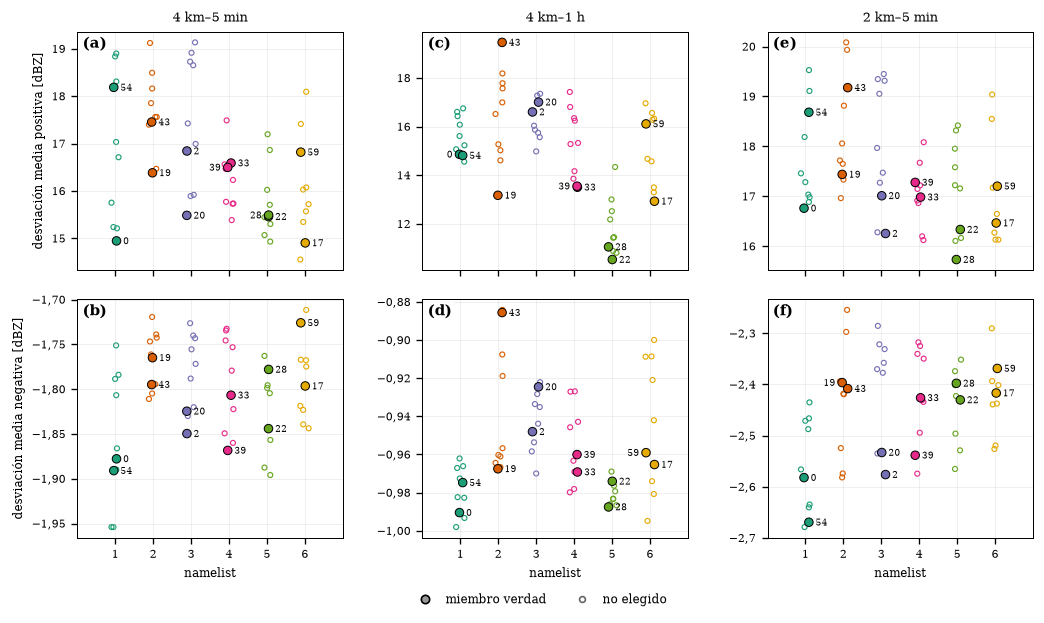

In [54]:
def draw_fig1(lang):
    L = LABELS[lang]
    fig, axes = plt.subplots(2, len(DATASETS), sharex=True, figsize=(nb.PAGE_W*1.5, nb.PAGE_W * 0.8),
                             gridspec_kw={"wspace": 0.3, "hspace": 0.12})
    for c, ds in enumerate(DATASETS):
        g = D1[D1.dataset == ds]
        x = g.namelist.to_numpy() + JITTER[ds]
        tt = g.verdad.to_numpy()
        col = [NL_COL[n] for n in g.namelist]
        for r, v in enumerate(("pos_mean", "neg_mean")):
            ax, y = axes[r, c], g[v].to_numpy()
            ax.scatter(x[~tt], y[~tt], s=9, facecolors="none",
                       edgecolors=[cc for cc, k in zip(col, tt) if not k], lw=0.7)
            ax.scatter(x[tt], y[tt], s=26, c=[cc for cc, k in zip(col, tt) if k], edgecolors="k", lw=0.6, zorder=3)
            for xi, yi, m in zip(x[tt], y[tt], g.member[tt]):
                left = m in LEFT.get((ds, v), ())
                ax.annotate(str(m), (xi, yi), xytext=(-4 if left else 4, -2), textcoords="offset points",
                            ha="right" if left else "left", fontsize=5.5)
            ax.set_xticks(range(1, 7))
            ax.tick_params(labelsize=6.5)
            ax.set_xlim(0, 7)
            if c == 0:
                ax.set_ylabel(L[v], fontsize=7)
            if r == 0:
                ax.set_title(DSL[ds], fontsize=8)
    for ax in axes[-1]:
        ax.set_xlabel(L["namelist"], fontsize=7)
    for a, l in zip(axes.ravel(order="F"), "abcdef"):
        nb.panel_label(a, l)
    fig.legend(handles=[Line2D([], [], ls="", marker="o", ms=5, color="0.6", mec="k", label=L["truth_member"]),
                        Line2D([], [], ls="", marker="o", ms=3.5, mfc="none", color="0.4", label=L["not_selected"])],
               loc="lower center", ncol=2, frameon=False, fontsize=7, bbox_to_anchor=(0.5, -0.01))
    return fig


nb.save(draw_fig1, "N4_fig1_seleccion", show=SHOW); plt.show()

## 2 · Resultado principal

$Z$ en las celdas alcanzadas y en la tormenta (columnas con máximo de la verdad ≥ 20 dBZ, dentro de las alcanzadas), sin las celdas NaN del subset y su vecindario.

In [55]:
H2, PT2 = central_band(ZS, ["domain", "dataset", "method", "ntemp"])
assert (H2.n_truths == len(TMS)).all()

# El RMSE del prior por dominio, de dos maneras: agrupado (las sumas de los 12 miembros y sus
# cuatro horas) y como la media de los 12 RMSE por miembro, que es lo que usaba el texto.
# En el medio, la raíz de la media de los 12 MSE por miembro: separa el efecto de Jensen
# (RMSE es cóncava en el MSE) del de pesar cada miembro por su cantidad de celdas.
p0 = PT2.xs(("TEnKF", 1), level=("method", "ntemp"))
mse_t = p0.RMSE_f ** 2
TXT = {("alcanzadas", "A"): 5.28, ("alcanzadas", "B"): 2.92, ("alcanzadas", "C"): 6.27}
prior = pd.DataFrame({
    "agrupado": H2.xs(("TEnKF", 1), level=("method", "ntemp")).RMSE_f,
    "√(media de los MSE)": np.sqrt(mse_t.groupby(level=["domain", "dataset"]).mean()),
    "media de los RMSE": p0.RMSE_f.groupby(level=["domain", "dataset"]).mean(),
    "desviación entre verdades": p0.RMSE_f.groupby(level=["domain", "dataset"]).std(ddof=1)})
prior["texto"] = [TXT.get(i, np.nan) for i in prior.index]
prior["agrupado − media"] = prior["agrupado"] - prior["media de los RMSE"]
print("RMSE del prior de Z por dominio [dBZ]:")
print(prior.rename(index=DSL, level="dataset").to_string(float_format=lambda v: f"{v:.3f}"))
w = p0.N.groupby(level=["domain", "dataset"]).apply(lambda s: s.max() / s.min())
print("\ncociente entre el miembro con más y con menos celdas en el dominio:",
      ", ".join(f"{dn} {DSL[ds]} {v:.2f}" for (dn, ds), v in w.items() if dn == "alcanzadas"))

RMSE del prior de Z por dominio [dBZ]:
                       agrupado  √(media de los MSE)  media de los RMSE  desviación entre verdades  texto  agrupado − media
domain     dataset                                                                                                         
alcanzadas 4 km–5 min     5.305                5.305              5.284                      0.498  5.280             0.021
           4 km–1 h       2.980                2.980              2.915                      0.646  2.920             0.065
           2 km–5 min     6.291                6.291              6.272                      0.503  6.270             0.018
observadas 4 km–5 min     6.486                6.486              6.460                      0.609    NaN             0.026
           4 km–1 h       4.531                4.532              4.434                      0.979    NaN             0.097
           2 km–5 min     7.815                7.815              7.792                      

In [56]:
TAB2 = {}
for dn in DOMAINS:
    t = H2.xs(dn, level="domain")
    TAB2[dn] = pd.DataFrame({c: [pm(r_[c], r_[f"{c}_sd"]) for _, r_ in t.iterrows()]
                             for c in ("F", "SS_RMSE", "SS_CRPS")},
                            index=pd.MultiIndex.from_tuples([(DSL[d], lab(m, n)) for d, m, n in t.index],
                                                            names=["dataset", "esquema"]))
    print(f"\n{dn}: Z, agrupado ± desviación entre los 12 miembros verdad")
    print(TAB2[dn].reindex([(DSL[d], lab(*s)) for d in DATASETS for s in SCHEMES]).to_string())
neg = (PT2.SS_RMSE < 0).groupby(level=["dataset", "method", "ntemp", "domain"]).sum().unstack("domain")
print(f"\nmiembros verdad (de {len(TMS)}) con SS_RMSE < 0:")
print(neg.rename(index=DSL, level="dataset").to_string())


alcanzadas: Z, agrupado ± desviación entre los 12 miembros verdad
                                 F         SS_RMSE         SS_CRPS
dataset    esquema                                                
4 km–5 min TEnKF-T1  0.577 ± 0.004  -0.288 ± 0.106  -1.584 ± 0.407
           TEnKF-T2  0.862 ± 0.005   0.415 ± 0.026   0.321 ± 0.053
           TEnKF-T3  0.793 ± 0.008   0.322 ± 0.036  -0.005 ± 0.091
           TEnKF-T4  0.847 ± 0.001   0.511 ± 0.033   0.337 ± 0.086
           TEnKF-T5  0.865 ± 0.005   0.577 ± 0.021   0.470 ± 0.045
           AOEI      0.591 ± 0.005  -0.259 ± 0.105  -1.495 ± 0.404
4 km–1 h   TEnKF-T1  0.687 ± 0.005  -0.445 ± 0.259  -2.293 ± 0.923
           TEnKF-T2  0.894 ± 0.002   0.390 ± 0.053   0.248 ± 0.112
           TEnKF-T3  0.820 ± 0.002   0.260 ± 0.085  -0.243 ± 0.253
           TEnKF-T4  0.873 ± 0.001   0.452 ± 0.057   0.240 ± 0.146
           TEnKF-T5  0.869 ± 0.002   0.490 ± 0.045   0.308 ± 0.111
           AOEI      0.701 ± 0.006  -0.451 ± 0.253  -2.265 ± 0

figures/es/N4_fig2_resultado.png  figures/en/N4_fig2_result.png


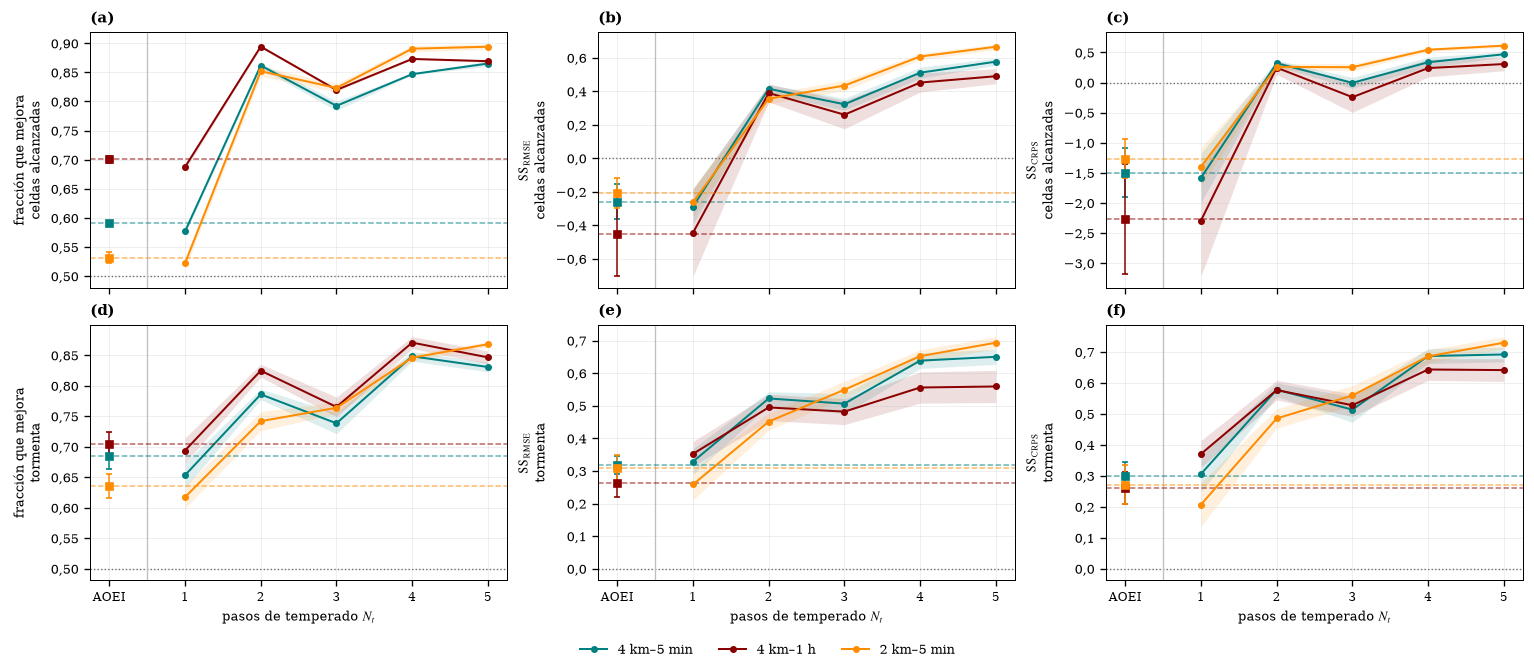

In [57]:
def draw_fig2(lang):
    V = nb.VOCAB[lang]
    rows = ("alcanzadas", "tormenta")
    fig, axes = plt.subplots(len(rows), 3, sharex=True, figsize=(nb.PAGE_W * 1.85, nb.PAGE_W * 0.8),
                             constrained_layout=True)
    for r, dn in enumerate(rows):
        for c, (col, ylab, guide) in enumerate((("F", V["frac_imp"], 0.5), ("SS_RMSE", V["ss_rmse"], 0.0),
                                                 ("SS_CRPS", V["ss_crps"], 0.0))):
            ax = axes[r, c]
            ax.axhline(guide, color="0.35", lw=0.8, ls=":", zorder=1)
            ladder(ax, H2.xs(dn, level="domain"), col)
            ax.set_ylabel(f"{ylab}\n{V[DOM_LABEL[dn]]}", fontsize=8)
            if r == len(rows) - 1:
                ax.set_xlabel(V["nt"], fontsize=8)
    fig.align_ylabels(axes)
    for a, l in zip(axes.ravel(), "abcdef"):
        a.set_title(f"({l})", loc="left", fontsize=9, fontweight="bold")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=3, frameon=False, fontsize=8)
    return fig


nb.save(draw_fig2, "N4_fig2_resultado", show=SHOW); plt.show()

## 3 · Observación única frente a observaciones múltiples

En las celdas observadas, con los mismos 12 miembros verdad. Observación única: los experimentos de N3 (`N3_sums_base.csv`: una observación, localización de 0,1 km, el punto asimilado), restringidos a los 12 miembros y a T1–T5 y AOEI. Observaciones múltiples: todas las observaciones juntas, 2 km, las celdas observadas válidas. Difieren dos factores a la vez: la interacción entre observaciones y la localización. Las dos con las mismas definiciones: sumas de los 12 miembros y las cuatro horas, banda entre los 12.

In [58]:
N3B = pd.read_csv(nb.DERIVED / "N3" / "N3_sums_base.csv", dtype={"hour": str})
S3 = N3B[(N3B["var"] == "obs") & N3B.dataset.isin(DATASETS)
         & np.array([(m, n) in SCHEMES for m, n in zip(N3B.method, N3B.ntemp)])]
S3_12 = S3[S3.tm.isin(TMS)]
H3 = {"single": central_band(S3_12, ["dataset", "method", "ntemp"])[0],
      "multi": H2.xs("observadas", level="domain")}
H3_60 = central_band(S3, ["dataset", "method", "ntemp"])[0]
for k in H3:
    assert (H3[k].n_truths == len(TMS)).all(), k
rows = []
for (ds, m, n), r_ in H3["multi"].iterrows():
    s1 = H3["single"].loc[(ds, m, n)]
    rows.append({"dataset": DSL[ds], "esquema": lab(m, n),
                 **{f"{c} única": pm(s1[c], s1[f"{c}_sd"]) for c in ("F", "SS_RMSE", "SS_CRPS")},
                 **{f"{c} múltiples": pm(r_[c], r_[f"{c}_sd"]) for c in ("F", "SS_RMSE", "SS_CRPS")},
                 **{f"{c} múltiples − única": f"{r_[c] - s1[c]:+.3f}" for c in ("F", "SS_RMSE", "SS_CRPS")},
                 **{f"{c} única (60)": f"{H3_60.loc[(ds, m, n), c]:.3f}" for c in ("F", "SS_RMSE", "SS_CRPS")}})
T3 = pd.DataFrame(rows).set_index(["dataset", "esquema"])
for c in ("F", "SS_RMSE", "SS_CRPS"):
    print(f"\n{c}: agrupado ± desviación entre los 12 miembros verdad")
    print(T3[[x for x in T3.columns if x.startswith(c + " ")]].reindex(
        [(DSL[d], lab(*s)) for d in DATASETS for s in SCHEMES]).to_string())


F: agrupado ± desviación entre los 12 miembros verdad
                           F única    F múltiples F múltiples − única F única (60)
dataset    esquema                                                                
4 km–5 min TEnKF-T1  0.744 ± 0.004  0.577 ± 0.004              -0.167        0.744
           TEnKF-T2  0.845 ± 0.004  0.862 ± 0.005              +0.017        0.844
           TEnKF-T3  0.818 ± 0.003  0.793 ± 0.008              -0.026        0.817
           TEnKF-T4  0.797 ± 0.003  0.847 ± 0.001              +0.050        0.797
           TEnKF-T5  0.845 ± 0.003  0.865 ± 0.005              +0.021        0.844
           AOEI      0.751 ± 0.003  0.591 ± 0.005              -0.160        0.751
4 km–1 h   TEnKF-T1  0.784 ± 0.005  0.687 ± 0.005              -0.096        0.782
           TEnKF-T2  0.857 ± 0.003  0.895 ± 0.002              +0.037        0.857
           TEnKF-T3  0.832 ± 0.004  0.820 ± 0.002              -0.012        0.831
           TEnKF-T4  0.816 ± 0.0

figures/es/N4_fig3_barrido.png  figures/en/N4_fig3_sweep.png


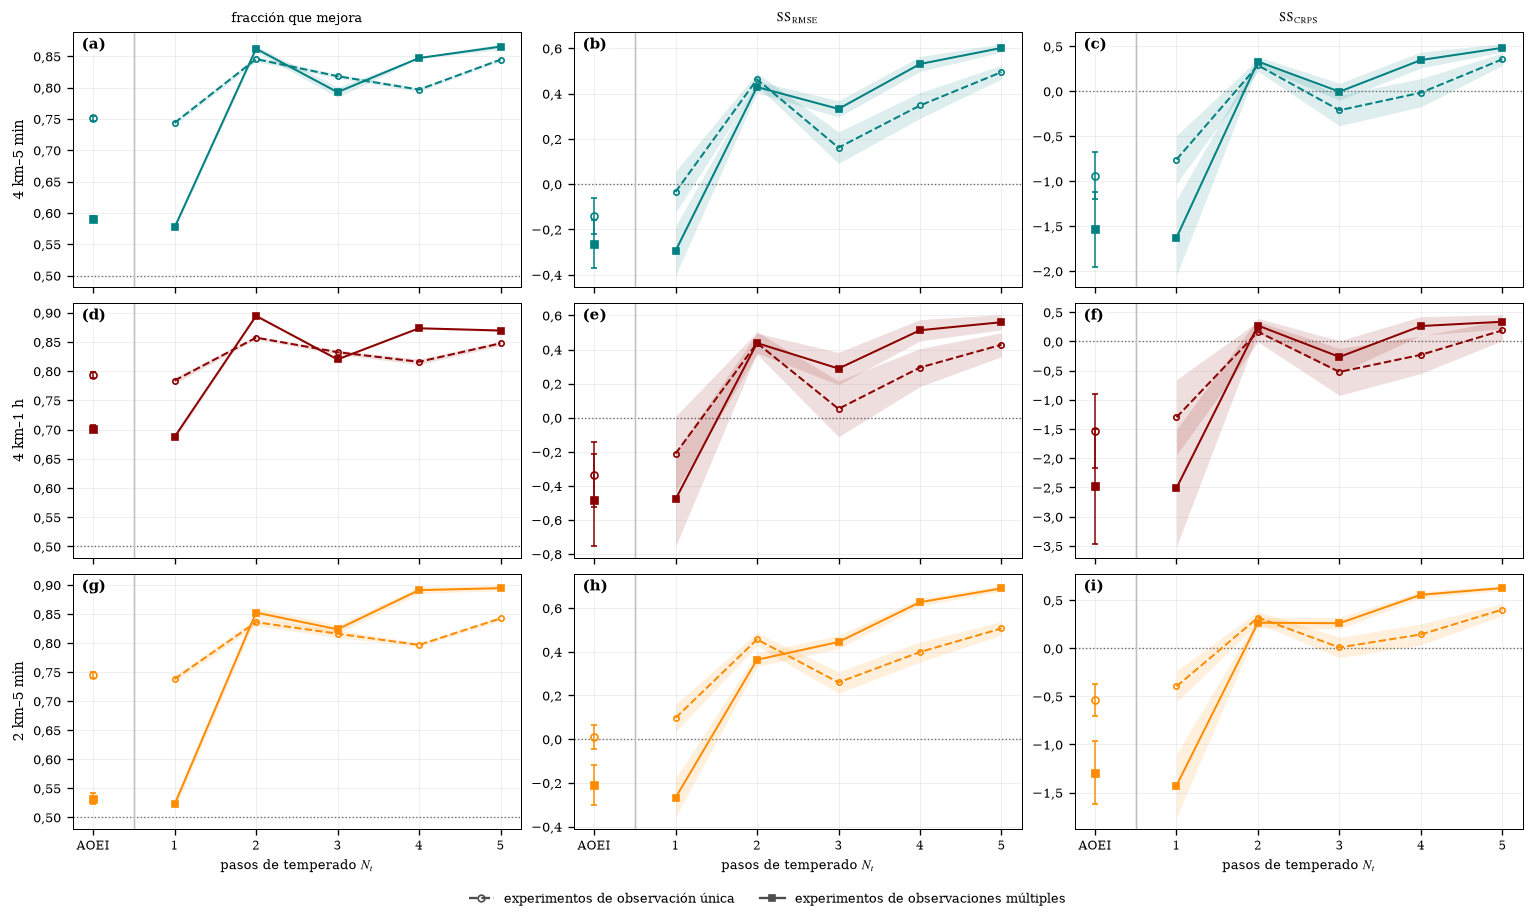

In [59]:
def draw_fig3(lang):
    V = nb.VOCAB[lang]
    sty = {"single": dict(ls="--", marker="o", mfc="none", amarker="o"),
           "multi": dict(ls="-", marker="s", mfc=None, amarker="s")}
    fig, axes = plt.subplots(len(DATASETS), 3, sharex=True, figsize=(nb.PAGE_W * 1.85, nb.PAGE_W * 1.1),
                             constrained_layout=True)
    for r, ds in enumerate(DATASETS):
        for c, (col, ylab, guide) in enumerate((("F", V["frac_imp"], 0.5), ("SS_RMSE", V["ss_rmse"], 0.0),
                                                 ("SS_CRPS", V["ss_crps"], 0.0))):
            ax = axes[r, c]
            ax.axhline(guide, color="0.35", lw=0.8, ls=":", zorder=1)
            for k in ("single", "multi"):
                st = dict(sty[k]); st["mfc"] = st["mfc"] or DS_COLORS[ds]
                ladder(ax, H3[k].loc[[ds]], col, label=None, style=st)
            if r == 0:
                ax.set_title(ylab, fontsize=8)
            if c == 0:
                ax.set_ylabel(DSL[ds], fontsize=8.5)
            if r == len(DATASETS) - 1:
                ax.set_xlabel(V["nt"], fontsize=8)
    for a, l in zip(axes.ravel(), "abcdefghi"):
        nb.panel_label(a, l)
    fig.legend(handles=[Line2D([], [], color="0.3", ms=4, ls="--", marker="o", mfc="none", label=V["single_obs"]),
                        Line2D([], [], color="0.3", ms=4, ls="-", marker="s", label=V["multi_obs"])],
               loc="outside lower center", ncol=2, frameon=False, fontsize=7.5)
    return fig


nb.save(draw_fig3, "N4_fig3_barrido", show=SHOW); plt.show()

## 4 · Estructura espacial

A a las 20 UTC, como ejemplo declarado: el nivel a 5 km y la fila del corte de N2. En cada celda, la fracción que mejora $F$ entre los experimentos que cambian en esa celda: uno por miembro verdad en que la celda está alcanzada y no excluida, hasta 12, con la banda de empate `TOL`. En blanco, las celdas donde cambian menos de `F_MAP_MIN_TRUTHS` = 6 miembros verdad. Contexto: la reflectividad verdad promediada sobre los 12 miembros, con su contorno de 20 dBZ sobre los paneles de $F$.

In [60]:
SP_KEYS = [lab(m, n) for m, n in SP_SCHEMES]
F_MAP_MIN_TRUTHS = 6
# una corrida (A 20 UTC): cada miembro verdad aporta a lo sumo un experimento por celda,
# así que n_change de la celda cuenta los miembros verdad que cambian
assert all(SPN[f"{k}_n_change_{key}"].max() <= len(TMS) for k in ("map", "sec") for key in SP_KEYS)


def cell_f(k, key):
    n, i = SPN[f"{k}_n_change_{key}"], SPN[f"{k}_n_imp_{key}"]
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(n >= F_MAP_MIN_TRUTHS, i / n, np.nan)


rows = []
for k, name in (("map", f"nivel {float(SPN['z_map_km']):g} km"), ("sec", f"fila {int(SPN['j'])}")):
    n = SPN[f"{k}_n_valid"]
    for key in SP_KEYS:
        f = cell_f(k, key)
        v, nc = n > 0, SPN[f"{k}_n_change_{key}"]
        ff = f[np.isfinite(f)]
        rows.append({"rebanada": name, "esquema": key, "celdas con miembros": int(v.sum()),
                     "con 12 miembros": (n == len(TMS)).sum() / n.size,
                     "F de la rebanada": SPN[f"{k}_n_imp_{key}"][v].sum() / nc[v].sum(),
                     "SS_RMSE de la rebanada": 1 - np.sqrt(SPN[f"{k}_se2_a_{key}"][v].sum() / SPN[f"{k}_se2_f_{key}"][v].sum()),
                     f"celdas con ≥ {F_MAP_MIN_TRUTHS} que cambian": ff.size, "de las con miembros": ff.size / v.sum(),
                     "con F > 0,5": (ff > 0.5).mean(), "con F = 0,5": (ff == 0.5).mean(),
                     "con F < 0,5": (ff < 0.5).mean()})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

  rebanada  esquema  celdas con miembros  con 12 miembros  F de la rebanada  SS_RMSE de la rebanada  celdas con ≥ 6 que cambian  de las con miembros  con F > 0,5  con F = 0,5  con F < 0,5
nivel 5 km TEnKF-T1               129174            0.927             0.439                  -0.539                       82484                0.639        0.376        0.040        0.584
nivel 5 km TEnKF-T2               129174            0.927             0.784                   0.328                       82484                0.639        0.829        0.041        0.130
  fila 180 TEnKF-T1                 2713            0.787             0.588                   0.056                        2118                0.781        0.559        0.093        0.348
  fila 180 TEnKF-T2                 2713            0.787             0.850                   0.500                        2117                0.780        0.946        0.025        0.029


/Users/Jorge/miniconda3/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/Users/Jorge/miniconda3/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/Users/Jorge/miniconda3/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/Users/Jorge/miniconda3/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/Users/Jorge/miniconda3/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/Users/Jorge/miniconda3/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/Users/Jorge/miniconda3/lib/

figures/es/N4_fig4_espacial.png  figures/en/N4_fig4_spatial.png


/Users/Jorge/miniconda3/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/Users/Jorge/miniconda3/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/Users/Jorge/miniconda3/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/Users/Jorge/miniconda3/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/Users/Jorge/miniconda3/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/Users/Jorge/miniconda3/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/Users/Jorge/miniconda3/lib/

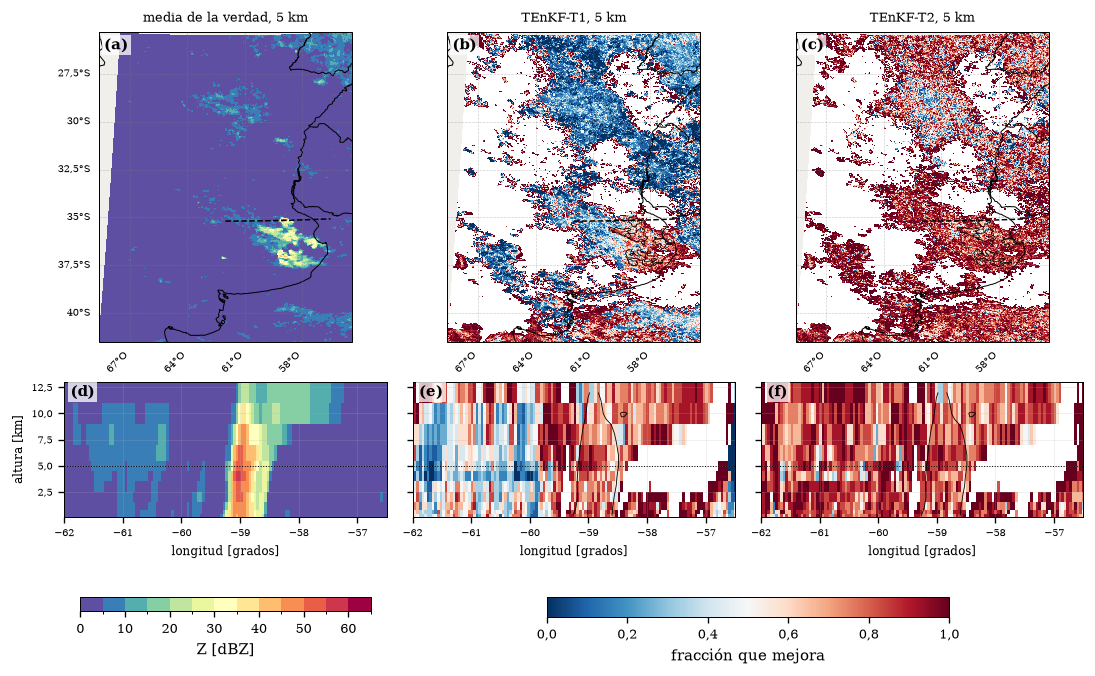

In [61]:
import cartopy.crs as ccrs
from matplotlib.colors import Normalize


def draw_fig4(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    PC_ = ccrs.PlateCarree()
    lats, lons = SPN["lats"], SPN["lons"]
    cl, cz = SPN["cut_lon"], SPN["z_km"]
    in_win = (cl >= nb.WIN_LON[0]) & (cl <= nb.WIN_LON[1])
    fnorm = Normalize(0.0, 1.0)            # divergente centrada en F = 0,5
    fcmap = plt.get_cmap(nb.CMAP_SKILL).with_extremes(bad="white")   # celdas sin F en blanco, también sobre el mapa
    zlab = nb.fmt(float(SPN["z_map_km"]), lang, "g")
    panels = [(f"{L['truth_mean']}, {zlab} km", None, dict(cmap=nb.DBZ_CMAP, norm=nb.DBZ_NORM))] + \
             [(f"{key}, {zlab} km", key, dict(cmap=fcmap, norm=fnorm)) for key in SP_KEYS]
    fig = plt.figure(figsize=(nb.PAGE_W * 1.6, nb.PAGE_W * 1.05))
    cols_ax = [[], [], []]
    gs = fig.add_gridspec(2, 3, height_ratios=[2.3, 1], hspace=0.18, wspace=0.08)
    for c, (title, key, kw) in enumerate(panels):
        ax = fig.add_subplot(gs[0, c], projection=PC_)
        cols_ax[c].append(ax)
        nb.setup_map(ax, xlocs=[-67, -64, -61, -58], ylocs=[-27.5, -30, -32.5, -35, -37.5, -40],
                     left_labels=(c == 0), bottom_labels=True)
        f = SPN["map_truth_mean"] if key is None else cell_f("map", key)
        pm_ = nb.map_field(ax, lats, lons, f, transform=PC_, **kw)
        if key is not None:
            ax.contour(lons, lats, SPN["map_truth_mean"].T, levels=[nb.STORM_THRESH_DBZ], colors="k",
                       linewidths=0.5, transform=PC_, zorder=3)
            pm_s = pm_
        else:
            pm_t = pm_
        ax.plot(cl[in_win], SPN["cut_lat"][in_win], color="k", lw=0.9, ls="--", transform=PC_, zorder=4)
        ax.set_title(title, fontsize=7.5)
        nb.panel_label(ax, "abc"[c])
        ax = fig.add_subplot(gs[1, c])
        cols_ax[c].append(ax)
        f = SPN["sec_truth_mean"] if key is None else cell_f("sec", key)
        ax.pcolormesh(cl, cz, f.T, shading="auto", rasterized=True, **kw)
        if key is not None:
            ax.contour(cl, cz, SPN["sec_truth_mean"].T, levels=[nb.STORM_THRESH_DBZ], colors="k", linewidths=0.5)
        ax.axhline(float(SPN["z_map_km"]), color="k", lw=0.6, ls=":")
        ax.set_xlim(*nb.WIN_LON)
        ax.set_xlabel(L["lon"], fontsize=7)
        if c == 0:
            ax.set_ylabel(L["height"], fontsize=7)
        else:
            ax.set_yticklabels([])
        ax.tick_params(labelsize=6)
        nb.panel_label(ax, "def"[c])
    fig.colorbar(pm_t, ax=cols_ax[0], orientation="horizontal", shrink=0.9, pad=0.12, label="Z [dBZ]")
    fig.colorbar(pm_s, ax=cols_ax[1] + cols_ax[2], orientation="horizontal", shrink=0.6, pad=0.12,
                 label=V["frac_imp"])
    return fig


nb.save(draw_fig4, "N4_fig4_espacial", show=SHOW); plt.show()

## 5 · El prior como predictor

La figura 3 de N3 en las celdas observadas válidas de las observaciones múltiples: mismos predictores, mismos bordes y la misma grilla gruesa, mismas definiciones dentro de cada bin, y los mismos umbrales `N_MIN_BIN` y `N_MIN_TRUTH`. TEnKF-T1 y TEnKF-T2. Como referencia, en línea fina, TEnKF-T1 de los experimentos de observación única con los mismos 12 miembros verdad (`N3_sums_bins.csv`). En la fila superior el eje de $\mathrm{SS}_\mathrm{RMSE}$ va de −1 a 1 y los bins por debajo se marcan con un triángulo en el borde, como en N3.

In [62]:
REBIN = {"dep_b": 2, "norm_innov": 2, "n_active_f_point": 6}
COARSE_ORIGIN = {"dep_b": 0, "norm_innov": 0, "n_active_f_point": 1}
PRED_ORDER = ("dep_b", "norm_innov", "n_active_f_point")
CURVE_SCHEMES = (("TEnKF", 1), ("TEnKF", 2))
LS = {1: "-", 2: "--"}
SS_LIM = (-1.0, 1.0)
FLOOR_DODGE = 0.15


def coarsen(b):
    out = []
    for p, g in b.groupby("predictor"):
        e, k, o = PRED_EDGES[p], REBIN[p], COARSE_ORIGIN[p]
        i = np.searchsorted(e, g.bin_left.to_numpy() + 1e-9) - 1
        assert (i >= o).all(), f"{p}: bins por debajo del origen de la grilla gruesa"
        c = (i - o) // k
        out.append(g.assign(bin_left=e[o + c * k], bin_right=e[np.minimum(o + (c + 1) * k, len(e) - 1)]))
    return pd.concat(out)


def binned(b, keys):
    kb = keys + ["bin_left", "bin_right"]
    t, _ = central_band(b, kb, n_min_truth=N_MIN_TRUTH)
    t["drawn"] = t.N >= N_MIN_BIN
    t["truths_out"] = len(TMS) - t.n_truths.fillna(0).astype(int)
    for c in STATS:
        t.loc[t.n_truths.fillna(0) < 2, f"{c}_sd"] = np.nan
    return t.sort_index()


T5 = binned(coarsen(PRED[PRED.method.eq("TEnKF") & PRED.ntemp.isin([1, 2])]), ["dataset", "method", "ntemp", "predictor"])
T5["share"] = T5.N / T5.groupby(level=["dataset", "method", "ntemp", "predictor"]).N.transform("sum")
N3BINS = pd.read_csv(nb.DERIVED / "N3" / "N3_sums_bins.csv")
R5 = binned(coarsen(N3BINS[(N3BINS["var"] == "obs") & (N3BINS.ntemp == 1) & (N3BINS.method == "TEnKF")
                            & N3BINS.tm.isin(TMS) & N3BINS.dataset.isin(DATASETS)]),
            ["dataset", "method", "ntemp", "predictor"])
r = T5.reset_index()
print(f"N_MIN_BIN = {N_MIN_BIN}: bins fuera de la figura, de {len(r)}:",
      r[~r.drawn].groupby(["predictor", "dataset"]).size().to_dict())
print(f"N_MIN_TRUTH = {N_MIN_TRUTH}: miembros verdad fuera de la banda, sumados sobre los bins dibujados:",
      r[r.drawn].groupby(["predictor", "dataset"]).truths_out.sum().to_dict())
a5 = r[r.drawn]
mins = a5.loc[a5.groupby(["predictor", "dataset", "ntemp"]).SS_RMSE.idxmin()]
print(f"\nfila superior, SS_RMSE por bin: mínimo y bins por debajo de {SS_LIM[0]:g}")
print(pd.DataFrame({"panel": mins.predictor.map(dict(zip(PRED_ORDER, "abc"))).values,
                    "dataset": mins.dataset.map(DSL).values,
                    "esquema": [lab(m, n) for m, n in zip(mins.method, mins.ntemp)],
                    "SS_RMSE mínimo": mins.SS_RMSE.round(3).values,
                    "bin": [f"[{lo:g}, {hi:g})" for lo, hi in zip(mins.bin_left, mins.bin_right)],
                    f"bins < {SS_LIM[0]:g}": a5.groupby(["predictor", "dataset", "ntemp"]).SS_RMSE.apply(
                        lambda v: int((v < SS_LIM[0]).sum())).values}).to_string(index=False))

N_MIN_BIN = 200: bins fuera de la figura, de 222: {('dep_b', 'B'): 2}
N_MIN_TRUTH = 20: miembros verdad fuera de la banda, sumados sobre los bins dibujados: {('dep_b', 'A'): 0, ('dep_b', 'B'): 12, ('dep_b', 'C'): 0, ('n_active_f_point', 'A'): 0, ('n_active_f_point', 'B'): 0, ('n_active_f_point', 'C'): 0, ('norm_innov', 'A'): 0, ('norm_innov', 'B'): 0, ('norm_innov', 'C'): 0}

fila superior, SS_RMSE por bin: mínimo y bins por debajo de -1
panel    dataset  esquema  SS_RMSE mínimo          bin  bins < -1
    a 4 km–5 min TEnKF-T1          -3.923      [-2, 2)          3
    a 4 km–5 min TEnKF-T2          -0.434       [2, 6)          0
    a   4 km–1 h TEnKF-T1          -4.803      [-2, 2)          3
    a   4 km–1 h TEnKF-T2          -0.424       [2, 6)          0
    a 2 km–5 min TEnKF-T1          -4.119      [-2, 2)          3
    a 2 km–5 min TEnKF-T2          -0.589       [2, 6)          0
    c 4 km–5 min TEnKF-T1          -0.516   [0.5, 6.5)          0
    c 4 km–5 min TEnKF-T2     

figures/es/N4_fig5_predictores.png  figures/en/N4_fig5_predictors.png


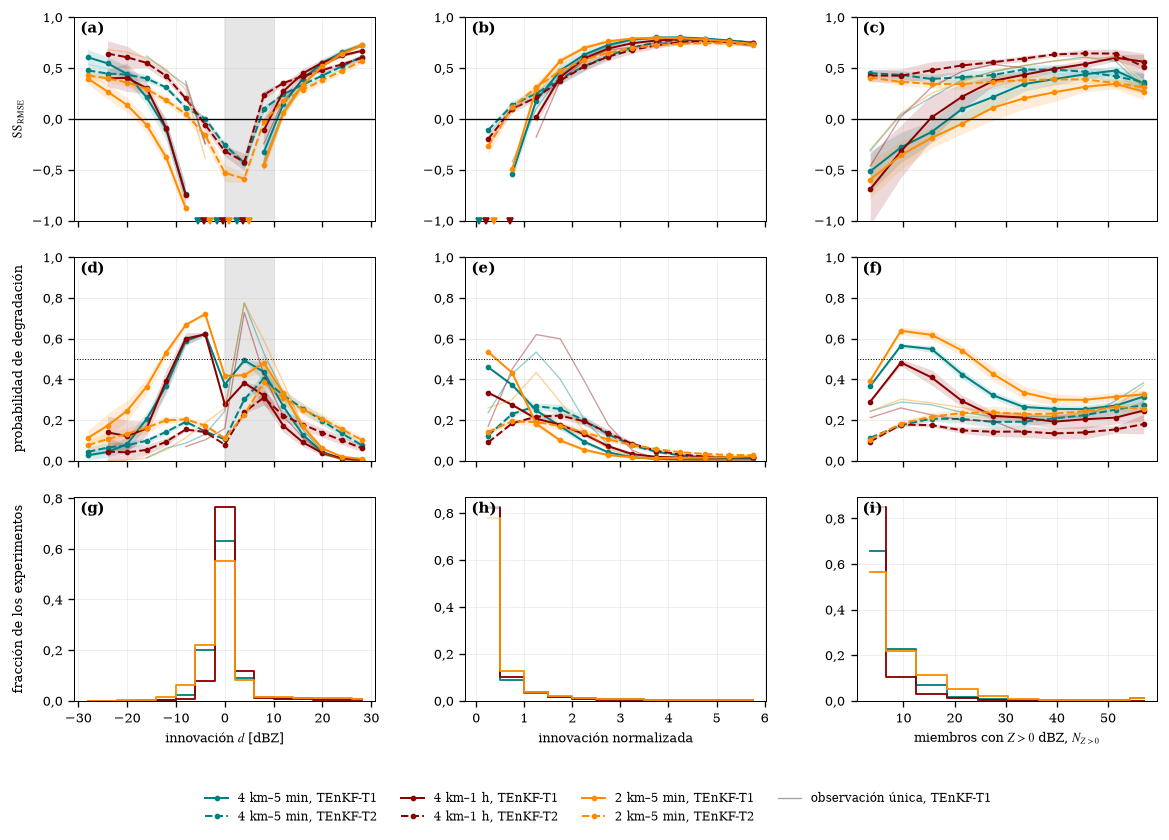

In [63]:
def draw_fig5(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    xl = {"dep_b": V["innov"], "norm_innov": L["norm_innov"], "n_active_f_point": L["n_active"]}
    fig, axes = plt.subplots(3, len(PRED_ORDER), sharex="col", figsize=(nb.PAGE_W * 1.7, nb.PAGE_W * 0.36 * 3),
                             gridspec_kw={"hspace": 0.18, "wspace": 0.30})
    for cc, p in enumerate(PRED_ORDER):
        for ds in DATASETS:
            ref = R5.loc[(ds, "TEnKF", 1, p)].reset_index()
            ref = ref[ref.drawn]
            xr = (0.5 * (ref.bin_left + ref.bin_right)).to_numpy()
            yr = ref.SS_RMSE.to_numpy()
            axes[0, cc].plot(xr, np.where(yr < SS_LIM[0], np.nan, yr), color=DS_COLORS[ds], lw=0.8, alpha=0.4)
            axes[1, cc].plot(xr, ref.P_deg, color=DS_COLORS[ds], lw=0.8, alpha=0.4)
            for m, n in CURVE_SCHEMES:
                d = T5.loc[(ds, m, n, p)].reset_index()
                d = d[d.drawn]
                xc = (0.5 * (d.bin_left + d.bin_right)).to_numpy()
                kw = dict(color=DS_COLORS[ds], ls=LS[n], lw=1.2)
                for row, col in ((0, "SS_RMSE"), (1, "P_deg")):
                    y, e = d[col].to_numpy(), d[f"{col}_sd"].to_numpy()
                    low = (y < SS_LIM[0]) if row == 0 else np.zeros(y.size, bool)
                    yv = np.where(low, np.nan, y)
                    axes[row, cc].plot(xc, yv, marker="o", ms=2.4, **kw,
                                       label=f"{DSL[ds]}, {lab(m, n)}" if row == 0 else None)
                    axes[row, cc].fill_between(xc, yv - e, yv + e, color=DS_COLORS[ds], alpha=0.15, lw=0)
                    if low.any():
                        k_ = DATASETS.index(ds) * len(CURVE_SCHEMES) + [c[1] for c in CURVE_SCHEMES].index(n)
                        width = (d.bin_right - d.bin_left).to_numpy()[low]
                        dx = (k_ - (len(DATASETS) * len(CURVE_SCHEMES) - 1) / 2) * FLOOR_DODGE * width
                        axes[row, cc].plot(xc[low] + dx, np.full(low.sum(), SS_LIM[0]), "v", ms=4.0,
                                           color=DS_COLORS[ds], mfc=DS_COLORS[ds] if n == 1 else "none",
                                           clip_on=False, zorder=6)
                if n == 1:
                    axes[2, cc].step(xc, d.share, where="mid", color=DS_COLORS[ds], lw=1.1)
        axes[0, cc].axhline(0, color="k", lw=0.8)
        axes[0, cc].set_ylim(*SS_LIM)
        axes[1, cc].axhline(0.5, color="k", lw=0.6, ls=":")
        axes[1, cc].set_ylim(0, 1)
        axes[2, cc].set_ylim(0, None)
        axes[2, cc].set_xlabel(xl[p], fontsize=7.5)
        if p == "dep_b":
            for rr in (0, 1):
                axes[rr, cc].axvspan(0.0, 10.0, color="0.9", zorder=0)
    axes[0, 0].set_ylabel(V["ss_rmse"], fontsize=7.5)
    axes[1, 0].set_ylabel(V["p_deg"], fontsize=7.5)
    axes[2, 0].set_ylabel(L["share"], fontsize=7.5)
    fig.align_ylabels(axes[:, 0])
    for a, l in zip(axes.ravel(), "abcdefghi"):
        nb.panel_label(a, l)
    h, l = axes[0, 0].get_legend_handles_labels()
    h.append(Line2D([], [], color="0.4", lw=0.8, alpha=0.6))
    l.append(L["single_t1"])
    fig.legend(h, l, loc="lower center", bbox_to_anchor=(0.5, -0.04), ncol=len(DATASETS) + 1, fontsize=7, frameon=False)
    return fig


nb.save(draw_fig5, "N4_fig5_predictores", show=SHOW); plt.show()

In [64]:
# Por tramo de la innovación, para el texto: probabilidad de degradación (entre los que
# cambian) y SS_RMSE, observación única (12 miembros) y observaciones múltiples. Tramos
# sobre bins enteros de 2 dBZ: d < 0, [0, 10) y 10 ≤ d < 30.
def tramos(b, src):
    d = b[(b.predictor == "dep_b") & (b.method == "TEnKF") & b.ntemp.isin([1, 2])]
    t = np.where(d.bin_right <= 0.0, "d < 0", np.where(d.bin_left >= 10.0, "10 ≤ d < 30", "[0, 10)"))
    g = d.assign(tramo=t).groupby(["dataset", "ntemp", "tramo"])[["n", "se2_f", "se2_a", "n_change", "n_imp"]].sum()
    return derive(g)[["P_deg", "SS_RMSE"]].assign(fuente=src)


TR = pd.concat([tramos(N3BINS[(N3BINS["var"] == "obs") & N3BINS.tm.isin(TMS) & N3BINS.dataset.isin(DATASETS)], "única"),
                tramos(PRED, "múltiples")]).reset_index()
TR = TR.pivot_table(index=["dataset", "ntemp"], columns=["tramo", "fuente"], values=["P_deg", "SS_RMSE"])
TR = TR.reindex(columns=["d < 0", "[0, 10)", "10 ≤ d < 30"], level="tramo")
print("probabilidad de degradación y SS_RMSE por tramo de la innovación, 12 miembros verdad")
print(TR.rename(index=DSL, level="dataset").to_string(float_format=lambda v: f"{v:.3f}"))

probabilidad de degradación y SS_RMSE por tramo de la innovación, 12 miembros verdad
                     P_deg                                           SS_RMSE                                          
tramo                d < 0         [0, 10)       10 ≤ d < 30           d < 0          [0, 10)        10 ≤ d < 30      
fuente           múltiples única múltiples única   múltiples única múltiples  única múltiples  única   múltiples única
dataset    ntemp                                                                                                      
4 km–5 min 1         0.442 0.134     0.444 0.594       0.109 0.131    -1.782 -0.533    -2.428 -3.188       0.526 0.493
           2         0.105 0.076     0.213 0.355       0.215 0.174     0.044  0.126    -0.187 -0.364       0.455 0.535
4 km–1 h   1         0.314 0.073     0.329 0.488       0.082 0.098    -2.664 -0.746    -2.825 -3.616       0.529 0.494
           2         0.072 0.042     0.161 0.329       0.158 0.115    -0.041  0.10

In [65]:
# ¿La innovación propia o la de los vecinos? La de los vecinos es la media de la innovación de
# las otras observaciones dentro del corte, pesada con exp(−d²/2) como en la LETKF y sin la
# propia celda. Probabilidad de degradación entre las celdas que cambian; separación: la del
# tramo más alto menos la del más bajo.
XC = N4["N4_innov_cross"]
XM = N4["N4_innov_corr"]
TR_ORDER = [t_ for t_, *_ in NBR_TRAMOS]
m_ = XM[XM.ntemp == 1].groupby("dataset")[["n", "sx", "sy", "sxx", "syy", "sxy"]].sum()
corr = ((m_.sxy / m_.n - m_.sx / m_.n * m_.sy / m_.n)
        / np.sqrt((m_.sxx / m_.n - (m_.sx / m_.n) ** 2) * (m_.syy / m_.n - (m_.sy / m_.n) ** 2)))
print("correlación entre la innovación propia y la de los vecinos: "
      + ",  ".join(f"{DSL[ds]} {corr[ds]:.3f}" for ds in DATASETS))
nn = XC[(XC.ntemp == 1) & (XC.vecinos == NBR_NONE)].groupby("dataset").n.sum()
print("celdas sin vecinos: " + ",  ".join(f"{DSL[ds]} {int(nn.get(ds, 0)):,}" for ds in DATASETS))
cell = lambda p, n: f"{p:.2f} ({int(n):,})"
for nt in (1, 2):
    print(f"\n══════ TEnKF-T{nt}: probabilidad de degradación (celdas que cambian) ══════")
    for ds in DATASETS:
        x = XC[(XC.dataset == ds) & (XC.ntemp == nt)].assign(n_change=lambda d: d.n_improved + d.n_degraded)
        print(f"\n{DSL[ds]}")
        for pred in ("propia", "vecinos"):
            g = x[x[pred] != NBR_NONE].groupby(pred)[["n_change", "n_degraded"]].sum().reindex(TR_ORDER)
            p = g.n_degraded / g.n_change
            print(f"  {pred:8s}" + "   ".join(f"{t_}: {cell(p[t_], g.n_change[t_])}" for t_ in TR_ORDER)
                  + f"   separación {p.max() - p.min():.2f}")
        g = x[x.vecinos != NBR_NONE].groupby(["propia", "vecinos"])[["n_change", "n_degraded"]].sum()
        P_ = (g.n_degraded / g.n_change).unstack().reindex(index=TR_ORDER, columns=TR_ORDER)
        N_ = g.n_change.unstack().reindex(index=TR_ORDER, columns=TR_ORDER)
        print(pd.DataFrame(np.vectorize(cell)(P_.values, N_.values),
                           index=[f"propia {r_}" for r_ in TR_ORDER],
                           columns=[f"vecinos {c}" for c in TR_ORDER]).to_string())

correlación entre la innovación propia y la de los vecinos: 4 km–5 min 0.885,  4 km–1 h 0.855,  2 km–5 min 0.901
celdas sin vecinos: 4 km–5 min 2,266,  4 km–1 h 4,157,  2 km–5 min 1,057

══════ TEnKF-T1: probabilidad de degradación (celdas que cambian) ══════

4 km–5 min
  propia  d < 0: 0.44 (28,334,113)   [0, 10): 0.44 (11,778,561)   d ≥ 10: 0.08 (2,249,375)   separación 0.36
  vecinos d < 0: 0.53 (23,528,496)   [0, 10): 0.30 (16,933,794)   d ≥ 10: 0.16 (1,898,205)   separación 0.37
                    vecinos d < 0   vecinos [0, 10)    vecinos d ≥ 10
propia d < 0    0.52 (18,810,283)  0.28 (9,396,811)    0.83 (126,132)
propia [0, 10)   0.59 (4,698,893)  0.34 (6,895,630)    0.68 (183,379)
propia d ≥ 10       0.27 (19,320)    0.16 (641,353)  0.05 (1,588,694)

4 km–1 h
  propia  d < 0: 0.31 (11,294,006)   [0, 10): 0.33 (6,650,781)   d ≥ 10: 0.06 (526,794)   separación 0.27
  vecinos d < 0: 0.45 (6,904,511)   [0, 10): 0.23 (11,138,794)   d ≥ 10: 0.16 (425,467)   separación 0.30
        

## 6 · Variables de estado

Solo SS: el runner clasificó las mejoras de las variables de estado sin banda de empate, así que no hay fracciones. El MSE y el CRPS del prior se calculan exactos sobre las celdas alcanzadas: el MSE desde la verdad y la media del prior del archivo `ref` (`N4_state_prior.csv`), el CRPS desde los 59 miembros del subset con el estimador del runner (`N4_state_crps.csv`). Los del posterior salen por cancelación con los escalares del runner, donde las celdas no alcanzadas no cambian: $\sum_\mathrm{alc} e_a^2 = \sum_\mathrm{alc} e_f^2 - (\sum_\mathrm{dom} e_f^2 - \sum_\mathrm{dom} e_a^2)$, y lo mismo con el CRPS. Dominios: tormenta dentro de las alcanzadas, aire claro alcanzado (global − tormenta), y las dos juntas. A diferencia de $Z$, no se quitan las celdas del vecindario de las NaN (los escalares no lo permiten).

En el aire claro alcanzado el CRPS del prior de los hidrometeoros es chico, así que la tabla de aire claro da también el CRPS medio por celda, del prior y del posterior. El mecanismo se prueba en los puntos de aire claro y viento débil de `N3_Step_by_step.ipynb`, sección 8.

El camino del CRPS se controla primero con la reflectividad, donde también existen los campos: el $\mathrm{SS}_\mathrm{CRPS}$ de $Z$ en las celdas alcanzadas con el prior desde el subset y el posterior por cancelación, contra el calculado desde `crps_f_ref_field` y `crps_a_ref_field`.

In [66]:
# El método, en la reflectividad. Las celdas son las del estado (alcanzadas, sin quitar el
# vecindario de las NaN), así que estos no son los números de Z de las secciones 2 y 3.
CK6 = N4["N4_crps_check"].assign(dom=lambda d: d.dom.map({"global": "alcanzadas", "storm": "tormenta"}))
CRPS_COLS = ["crps_f_subset", "crps_a_metodo", "crps_f_campos", "crps_a_campos"]


def ss_two_ways(s):
    return pd.DataFrame({"método": 1 - s.crps_a_metodo / s.crps_f_subset,
                         "campos": 1 - s.crps_a_campos / s.crps_f_campos}, index=s.index)


print("Σ CRPS de Z por (corrida, miembro verdad, esquema, dominio), máx dif. relativa:")
for a, b in (("crps_f_subset", "crps_f_campos"), ("crps_a_metodo", "crps_a_campos")):
    print(f"  {a} contra {b}: {(np.abs(CK6[a] - CK6[b]) / CK6[b]).max():.1e}")
zp = ss_two_ways(CK6.groupby(["dom", "dataset", "method", "ntemp"])[CRPS_COLS].sum())
zt = ss_two_ways(CK6.groupby(["dom", "dataset", "method", "ntemp", "tm"])[CRPS_COLS].sum())
print(f"SS_CRPS de Z, máx |método − campos|: agrupado {(zp['método'] - zp['campos']).abs().max():.1e}, "
      f"por miembro verdad {(zt['método'] - zt['campos']).abs().max():.1e}")
tab = zp.assign(**{"dif.": zp["método"] - zp["campos"]})
tab.index = [f"{dn}, {DSL[d]} {lab(m, n)}" for dn, d, m, n in tab.index]
print("\nSS_CRPS de Z en las celdas alcanzadas, agrupado, por los dos caminos:")
print(tab.to_string(formatters={"método": "{:+.4f}".format, "campos": "{:+.4f}".format, "dif.": "{:+.1e}".format}))

Σ CRPS de Z por (corrida, miembro verdad, esquema, dominio), máx dif. relativa:
  crps_f_subset contra crps_f_campos: 1.1e-09
  crps_a_metodo contra crps_a_campos: 1.7e-09
SS_CRPS de Z, máx |método − campos|: agrupado 3.2e-11, por miembro verdad 1.0e-09

SS_CRPS de Z en las celdas alcanzadas, agrupado, por los dos caminos:
                                 método  campos     dif.
alcanzadas, 4 km–5 min AOEI     -1.4951 -1.4951 -1.3e-11
alcanzadas, 4 km–5 min TEnKF-T1 -1.5841 -1.5841 -1.1e-11
alcanzadas, 4 km–5 min TEnKF-T2 +0.3213 +0.3213 +1.6e-11
alcanzadas, 4 km–5 min TEnKF-T3 -0.0048 -0.0048 +1.6e-11
alcanzadas, 4 km–5 min TEnKF-T4 +0.3374 +0.3374 +1.1e-11
alcanzadas, 4 km–5 min TEnKF-T5 +0.4697 +0.4697 +6.9e-13
alcanzadas, 4 km–1 h AOEI       -2.2658 -2.2658 +5.8e-13
alcanzadas, 4 km–1 h TEnKF-T1   -2.2937 -2.2937 +1.2e-11
alcanzadas, 4 km–1 h TEnKF-T2   +0.2477 +0.2477 -1.4e-11
alcanzadas, 4 km–1 h TEnKF-T3   -0.2429 -0.2429 +1.3e-11
alcanzadas, 4 km–1 h TEnKF-T4   +0.2402 +0.2402 

In [67]:
ST_VARS = tuple(nb.VARS)
KEY6 = ["dataset", "hour", "tm", "method", "ntemp", "var"]
parts = []
for v in ST_VARS:
    for dom in ("global", "storm"):
        sse = lambda s: SCAL[f"n_rmse_{s}_{dom}_{v}"] * SCAL[f"rmse_{s}_{dom}_{v}"] ** 2
        scr = lambda s: SCAL[f"n_crps_{s}_{dom}_{v}"] * SCAL[f"crps_{s}_{dom}_{v}"]
        parts.append(SCAL[["dataset", "hour", "tm", "method", "ntemp"]]
                     .assign(var=v, dom=dom, Q=sse("f") - sse("a"), Qc=scr("f") - scr("a")))
Q6 = pd.concat(parts).set_index(KEY6 + ["dom"])[["Q", "Qc"]]
Q6 = {"tormenta": Q6.xs("storm", level="dom"),
      "aire claro": Q6.xs("global", level="dom") - Q6.xs("storm", level="dom")}
E6 = N4["N4_state_prior"].merge(N4["N4_state_crps"], on=["dataset", "hour", "tm", "var", "dominio"],
                                suffixes=("", "_crps"), validate="one_to_one")
assert (E6.n == E6.n_crps).all(), "el CRPS y el error del prior no tienen las mismas celdas"
E6 = E6.set_index(["dataset", "hour", "tm", "var", "dominio"])[["n", "sum_err2", "sum_crps_f"]]
rows = []
for dn in ("tormenta", "aire claro"):
    q = Q6[dn].reset_index()
    e = E6.xs(dn, level="dominio").reset_index()
    rows.append(q.merge(e, on=["dataset", "hour", "tm", "var"], validate="many_to_one").assign(domain=dn))
ST6 = pd.concat(rows)
ST6 = pd.concat([ST6, ST6.groupby(KEY6, as_index=False)[["Q", "Qc", "n", "sum_err2", "sum_crps_f"]].sum()
                 .assign(domain="alcanzadas")])
ST6 = ST6.assign(se2_f=ST6.sum_err2, se2_a=ST6.sum_err2 - ST6.Q,
                 scrps_f=ST6.sum_crps_f, scrps_a=ST6.sum_crps_f - ST6.Qc)
assert (ST6.se2_a > 0).all(), "MSE del posterior no positivo"
assert (ST6.scrps_a > 0).all(), "CRPS del posterior no positivo"
H6, PT6 = central_band(ST6, ["var", "domain", "dataset", "method", "ntemp"])
assert (H6.n_truths == len(TMS)).all()
for dn in ("tormenta", "aire claro", "alcanzadas"):
    t = H6.xs(dn, level="domain")
    for st in ("SS_RMSE", "SS_CRPS"):
        tab = pd.Series([pm(r_[st], r_[f"{st}_sd"]) for _, r_ in t.iterrows()], index=t.index)
        tab = tab.unstack("var")[list(ST_VARS)]
        tab.index = [f"{DSL[d]} {lab(m, n)}" for d, m, n in tab.index]
        print(f"\n{st} de las variables de estado, {dn}: agrupado ± desviación entre los 12 miembros verdad")
        print(tab.to_string())


SS_RMSE de las variables de estado, tormenta: agrupado ± desviación entre los 12 miembros verdad
var                             qg             qr             qs               T               P               u               v               w
4 km–5 min AOEI      0.064 ± 0.024  0.078 ± 0.019  0.069 ± 0.197   0.074 ± 0.018   0.031 ± 0.010   0.041 ± 0.011   0.018 ± 0.010   0.015 ± 0.009
4 km–5 min TEnKF-T1  0.144 ± 0.040  0.138 ± 0.037  0.136 ± 0.887   0.114 ± 0.095  -0.013 ± 0.049  -0.000 ± 0.042  -0.061 ± 0.044  -0.052 ± 0.037
4 km–5 min TEnKF-T2  0.294 ± 0.053  0.306 ± 0.039  0.229 ± 0.676   0.090 ± 0.112  -0.026 ± 0.055  -0.021 ± 0.043  -0.082 ± 0.048  -0.045 ± 0.034
4 km–5 min TEnKF-T3  0.290 ± 0.052  0.301 ± 0.040  0.210 ± 0.815   0.095 ± 0.103  -0.013 ± 0.056  -0.002 ± 0.036  -0.062 ± 0.041  -0.023 ± 0.029
4 km–5 min TEnKF-T4  0.309 ± 0.054  0.331 ± 0.042  0.222 ± 0.765   0.067 ± 0.081  -0.024 ± 0.049  -0.010 ± 0.034  -0.070 ± 0.038  -0.076 ± 0.042
4 km–5 min TEnKF-T5  0.313 ± 0.0

In [68]:
# Hidrometeoros en aire claro alcanzado: el CRPS medio por celda del prior y del posterior,
# agrupado (ΣCRPS / ΣN sobre los 12 miembros verdad y sus cuatro horas), junto a SS_CRPS y
# SS_RMSE. Como escala, el CRPS medio del prior en tormenta alcanzada. En g/kg.
CRPS_FMT = {c: "{:.2e}".format for c in ("CRPS_f [g/kg]", "CRPS_a [g/kg]", "CRPS_f tormenta [g/kg]")}
CRPS_FMT |= {c: "{:+.3f}".format for c in ("SS_CRPS", "SS_RMSE")}
for v in HYDRO:
    t = H6.xs((v, "aire claro"), level=("var", "domain"))
    s = H6.xs((v, "tormenta"), level=("var", "domain"))
    tab = pd.DataFrame({"CRPS_f [g/kg]": 1e3 * t.CRPS_f, "CRPS_a [g/kg]": 1e3 * t.CRPS_a,
                        "SS_CRPS": t.SS_CRPS, "SS_RMSE": t.SS_RMSE, "CRPS_f tormenta [g/kg]": 1e3 * s.CRPS_f})
    tab.index = [f"{DSL[d]} {lab(m, n)}" for d, m, n in tab.index]
    print(f"\n{v}, aire claro alcanzado (agrupado)")
    print(tab.to_string(formatters=CRPS_FMT))


qg, aire claro alcanzado (agrupado)
                    CRPS_f [g/kg] CRPS_a [g/kg] SS_CRPS SS_RMSE CRPS_f tormenta [g/kg]
4 km–5 min AOEI          4.55e-04      2.57e-03  -4.643  +0.265               8.24e-02
4 km–5 min TEnKF-T1      4.55e-04      2.90e-03  -5.370  +0.145               8.24e-02
4 km–5 min TEnKF-T2      4.55e-04      3.45e-04  +0.243  +0.839               8.24e-02
4 km–5 min TEnKF-T3      4.55e-04      8.57e-04  -0.884  +0.722               8.24e-02
4 km–5 min TEnKF-T4      4.55e-04      5.19e-04  -0.142  +0.881               8.24e-02
4 km–5 min TEnKF-T5      4.55e-04      4.34e-04  +0.046  +0.881               8.24e-02
4 km–1 h AOEI            1.43e-04      1.20e-03  -7.441  +0.263               9.79e-02
4 km–1 h TEnKF-T1        1.43e-04      1.30e-03  -8.108  +0.166               9.79e-02
4 km–1 h TEnKF-T2        1.43e-04      1.32e-04  +0.076  +0.871               9.79e-02
4 km–1 h TEnKF-T3        1.43e-04      3.66e-04  -1.561  +0.777               9.79e-02
4 km–1

figures/es/N4_fig6_w.png  figures/en/N4_fig6_w.png


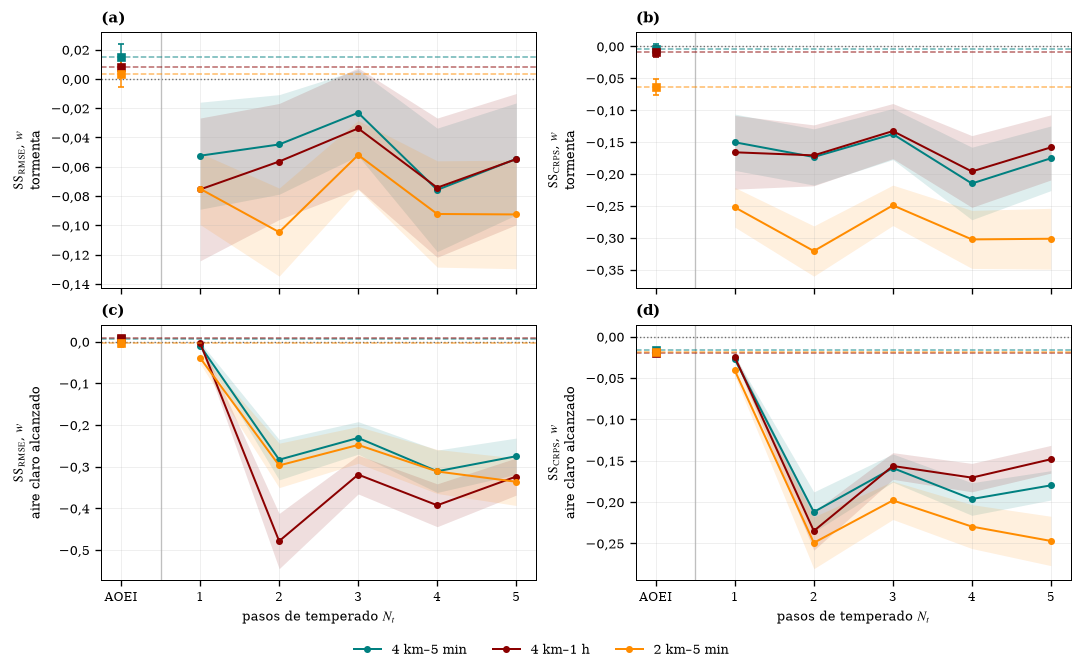

In [69]:
def draw_fig6(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    doms = (("tormenta", V["dom_storm"]), ("aire claro", L["clear_reached"]))
    fig, axes = plt.subplots(2, 2, sharex=True, figsize=(nb.PAGE_W * 1.3, nb.PAGE_W * 0.8),
                             constrained_layout=True)
    for r, (dn, dlab) in enumerate(doms):
        for c, st in enumerate(("SS_RMSE", "SS_CRPS")):
            ax = axes[r, c]
            ax.axhline(0.0, color="0.35", lw=0.8, ls=":", zorder=1)
            ladder(ax, H6.xs(("w", dn), level=("var", "domain")), st)
            ax.set_ylabel(f"{V[st.lower()]}, $w$\n{dlab}", fontsize=8)
            if r == len(doms) - 1:
                ax.set_xlabel(V["nt"], fontsize=8)
    fig.align_ylabels(axes)
    for a, l in zip(axes.ravel(), "abcd"):
        a.set_title(f"({l})", loc="left", fontsize=9, fontweight="bold")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=3, frameon=False, fontsize=8)
    return fig


nb.save(draw_fig6, "N4_fig6_w", show=SHOW); plt.show()

In [70]:
# qs en tormenta: en algunos miembros verdad el MSE del prior es casi nulo y el análisis lo
# multiplica. Por miembro, SS_RMSE y SS_CRPS de qs en tormenta alcanzada, y el MSE del
# prior por la microfísica del miembro verdad.
q = PT6.xs(("qs", "tormenta"), level=("var", "domain")).reset_index()
q = q.assign(microfisica=q.tm.map(MICRO), namelist=q.tm.map(NAMELIST))
mse = (q[(q.method == "TEnKF") & (q.ntemp == 1)].assign(mse=lambda d: (d.RMSE_f * 1e3) ** 2)
       .pivot_table(index=["microfisica", "namelist", "tm"], columns="dataset", values="mse"))
print("MSE del prior de qs en tormenta alcanzada, por miembro verdad [(g/kg)²]:")
print(mse.sort_index().rename(columns=DSL).to_string(float_format=lambda x: f"{x:.4f}"))
for st in ("SS_RMSE", "SS_CRPS"):
    rows = []
    for (ds, m, n), g in q.groupby(["dataset", "method", "ntemp"]):
        rows.append({"dataset": DSL[ds], "esquema": lab(m, n), "SS > 0": int((g[st] > 0).sum()),
                     "SS < 0": int((g[st] < 0).sum()), "mín": g[st].min(), "máx": g[st].max(),
                     "SS > 0: WSM6/Lin": f"{int(((g[st] > 0) & (g.microfisica == 'WSM6')).sum())}/"
                                         f"{int(((g[st] > 0) & (g.microfisica == 'Lin')).sum())}"})
    print(f"\n{st} de qs en tormenta, por miembro verdad:")
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:+.2f}"))

MSE del prior de qs en tormenta alcanzada, por miembro verdad [(g/kg)²]:
dataset                  4 km–5 min  4 km–1 h  2 km–5 min
microfisica namelist tm                                  
Lin         4        33      0.0031    0.0012      0.0038
                     39      0.0027    0.0013      0.0045
            5        22      0.0023    0.0006      0.0038
                     28      0.0027    0.0006      0.0044
            6        17      0.0032    0.0013      0.0048
                     59      0.0029    0.0010      0.0043
WSM6        1        0       0.0454    0.0286      0.0728
                     54      0.0997    0.0358      0.1250
            2        19      0.0642    0.0184      0.1060
                     43      0.0946    0.1684      0.1257
            3        2       0.0537    0.1019      0.0693
                     20      0.0616    0.1037      0.0995

SS_RMSE de qs en tormenta, por miembro verdad:
   dataset  esquema  SS > 0  SS < 0   mín   máx SS > 0: WSM6/Lin
4 

## 7 · Dispersión frente a error

Dispersión total $= \sqrt{(N_e+1)/N_e \cdot}$ media de la varianza de los miembros (ddof = 1), la misma definición que el runner, contra el RMSE de la media. $Z$: exacto en las celdas alcanzadas, desde las sumas de los campos. Cada cociente se calcula sobre las sumas de los 12 miembros y las cuatro horas; la banda, entre los 12 miembros. El cociente de RMSE posterior / prior es $1 - \mathrm{SS}_\mathrm{RMSE}$.

In [71]:
NE7 = int(SCAL.Ne.iloc[0])
assert SCAL.Ne.nunique() == 1
F7 = (NE7 + 1) / NE7


def ratios(s):
    return pd.DataFrame({"ratio_f": np.sqrt(F7 * s.ssp2_f / s.se2_f), "ratio_a": np.sqrt(F7 * s.ssp2_a / s.se2_a),
                         "contr_spread": np.sqrt(s.ssp2_a / s.ssp2_f), "contr_rmse": np.sqrt(s.se2_a / s.se2_f)},
                        index=s.index)


K7 = ["domain", "dataset", "method", "ntemp"]
C7 = ratios(ZS.groupby(K7)[["se2_f", "se2_a", "ssp2_f", "ssp2_a"]].sum())
P7 = ratios(ZS.set_index(K7 + ["tm"])[["se2_f", "se2_a", "ssp2_f", "ssp2_a"]])
H7 = C7.join(P7.groupby(level=K7).std(ddof=1).add_suffix("_sd"))
for dn in ("alcanzadas", "tormenta"):
    t = H7.xs(dn, level="domain")
    print(f"\n{dn}: agrupado ± desviación entre los 12 miembros verdad")
    print(pd.DataFrame({c: [pm(r_[c], r_[f"{c}_sd"]) for _, r_ in t.iterrows()]
                        for c in ("ratio_f", "ratio_a", "contr_spread", "contr_rmse")},
                       index=[f"{DSL[d]} {lab(m, n)}" for d, m, n in t.index]).to_string())


alcanzadas: agrupado ± desviación entre los 12 miembros verdad
                           ratio_f        ratio_a   contr_spread     contr_rmse
4 km–5 min AOEI      1.066 ± 0.108  0.550 ± 0.012  0.649 ± 0.006  1.259 ± 0.105
4 km–5 min TEnKF-T1  1.066 ± 0.108  0.520 ± 0.016  0.628 ± 0.008  1.288 ± 0.106
4 km–5 min TEnKF-T2  1.066 ± 0.108  0.921 ± 0.065  0.505 ± 0.003  0.585 ± 0.026
4 km–5 min TEnKF-T3  1.066 ± 0.108  0.618 ± 0.053  0.393 ± 0.005  0.678 ± 0.036
4 km–5 min TEnKF-T4  1.066 ± 0.108  0.784 ± 0.043  0.360 ± 0.003  0.489 ± 0.033
4 km–5 min TEnKF-T5  1.066 ± 0.108  0.853 ± 0.078  0.339 ± 0.004  0.423 ± 0.021
4 km–1 h AOEI        1.060 ± 0.222  0.454 ± 0.020  0.622 ± 0.005  1.451 ± 0.253
4 km–1 h TEnKF-T1    1.060 ± 0.222  0.445 ± 0.023  0.606 ± 0.012  1.445 ± 0.259
4 km–1 h TEnKF-T2    1.060 ± 0.222  0.877 ± 0.131  0.505 ± 0.006  0.610 ± 0.053
4 km–1 h TEnKF-T3    1.060 ± 0.222  0.597 ± 0.072  0.417 ± 0.007  0.740 ± 0.085
4 km–1 h TEnKF-T4    1.060 ± 0.222  0.756 ± 0.107  0.391

figures/es/N4_fig7_dispersion.png  figures/en/N4_fig7_spread.png


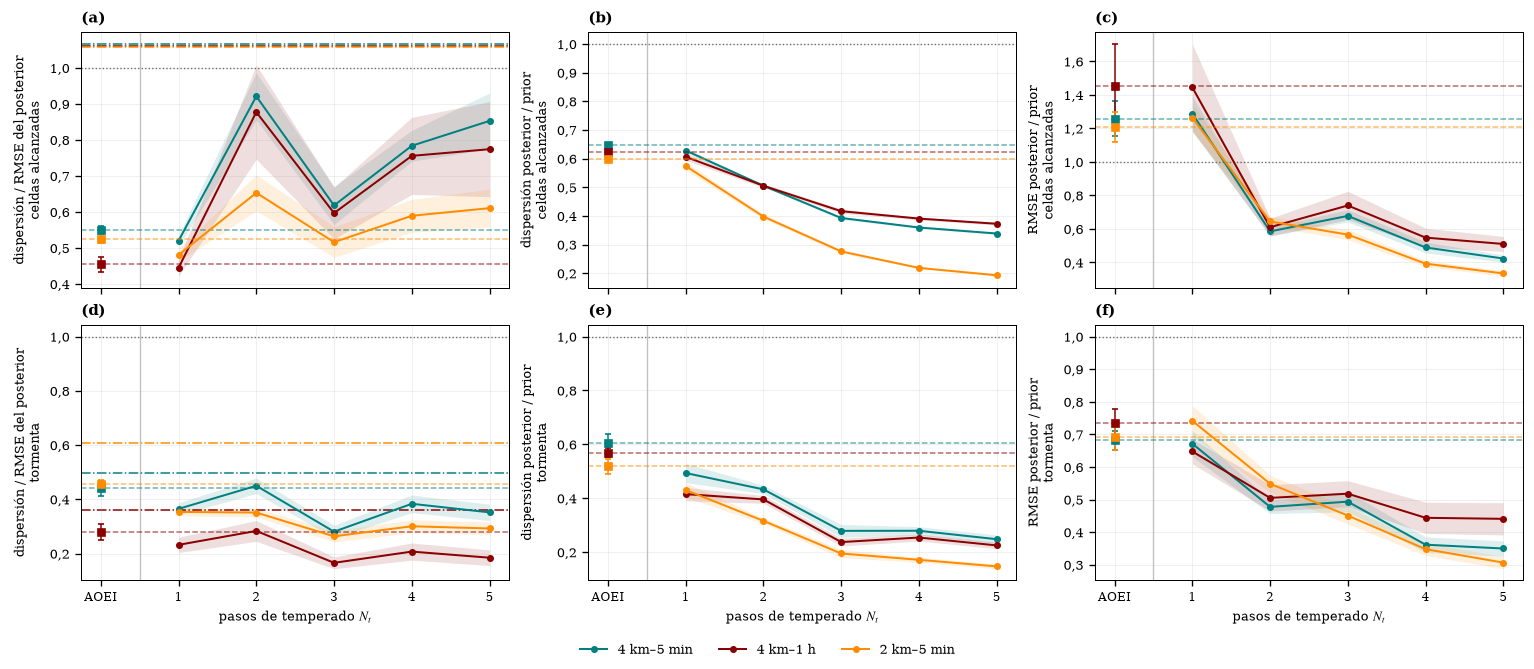

In [72]:
def draw_fig7(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    rows = ("alcanzadas", "tormenta")
    fig, axes = plt.subplots(len(rows), 3, sharex=True, figsize=(nb.PAGE_W * 1.85, nb.PAGE_W * 0.8),
                             constrained_layout=True)
    for r, dn in enumerate(rows):
        for c, (q_, ylab) in enumerate((("ratio_a", L["ratio_a"]), ("contr_spread", L["contr_spread"]),
                                        ("contr_rmse", L["contr_rmse"]))):
            ax = axes[r, c]
            ax.axhline(1.0, color="0.35", lw=0.8, ls=":", zorder=1)
            t = H7.xs(dn, level="domain")
            ladder(ax, t, q_)
            if q_ == "ratio_a":          # el prior, igual para todos los esquemas
                for ds in DATASETS:
                    ax.axhline(t.loc[(ds, "TEnKF", 1), "ratio_f"], color=DS_COLORS[ds], lw=0.9, ls="-.", zorder=1)
            ax.set_ylabel(f"{ylab}\n{V[DOM_LABEL[dn]]}", fontsize=7.5)
            if r == len(rows) - 1:
                ax.set_xlabel(V["nt"], fontsize=8)
    fig.align_ylabels(axes)
    for a, l in zip(axes.ravel(), "abcdef"):
        a.set_title(f"({l})", loc="left", fontsize=9, fontweight="bold")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=3, frameon=False, fontsize=8)
    return fig


nb.save(draw_fig7, "N4_fig7_dispersion", show=SHOW); plt.show()

In [73]:
# El estado, exacto en las celdas alcanzadas: las ocho variables, tormenta y aire claro
# alcanzado, T1, T2, T5 y AOEI. Prior: varianza de los 59 desde el subset y error desde el
# ref; posterior por cancelación con los escalares del runner. Cociente de las sumas sobre
# los 12 miembros y sus cuatro horas.
SPR = N4["N4_state_spread"]
SPR = SPR[SPR.dominio != "completo"].groupby(["dataset", "tm", "var", "dominio"]).sum_var_f.sum()
EPR = N4["N4_state_prior"]
EPR = EPR[EPR.dominio != "completo"].groupby(["dataset", "tm", "var", "dominio"]).sum_err2.sum()
parts = []
for v in ST_VARS:
    for dom in ("global", "storm"):
        g = SCAL[["dataset", "tm", "method", "ntemp"]].assign(var=v, dom=dom)
        dvar = (SCAL[f"n_spread_f_{dom}_{v}"] * SCAL[f"spread_f_{dom}_{v}"] ** 2
                - SCAL[f"n_spread_a_{dom}_{v}"] * SCAL[f"spread_a_{dom}_{v}"] ** 2) / F7
        Q = (SCAL[f"n_rmse_f_{dom}_{v}"] * SCAL[f"rmse_f_{dom}_{v}"] ** 2
             - SCAL[f"n_rmse_a_{dom}_{v}"] * SCAL[f"rmse_a_{dom}_{v}"] ** 2)
        parts.append(g.assign(dvar=dvar, Q=Q))
D7 = pd.concat(parts).groupby(["dataset", "tm", "method", "ntemp", "var", "dom"])[["dvar", "Q"]].sum()
D7s, D7g = D7.xs("storm", level="dom"), D7.xs("global", level="dom")
rows = []
for name, d in (("tormenta", D7s), ("aire claro", D7g - D7s)):
    key = d.reset_index().set_index(["dataset", "tm", "var"]).index
    vf = SPR.xs(name, level="dominio").reindex(key).to_numpy()
    ef = EPR.xs(name, level="dominio").reindex(key).to_numpy()
    rows.append(pd.DataFrame({"ssp2_f": vf, "ssp2_a": vf - d.dvar.to_numpy(), "se2_f": ef, "se2_a": ef - d.Q.to_numpy()},
                             index=d.index).assign(domain=name))
S7 = pd.concat(rows).reset_index()
assert (S7[["ssp2_f", "ssp2_a", "se2_f", "se2_a"]] > 0).all().all(), "varianza o MSE no positivos en celdas alcanzadas"
T7 = ratios(S7.groupby(["var", "domain", "dataset", "method", "ntemp"])[["ssp2_f", "ssp2_a", "se2_f", "se2_a"]].sum())
S7_SCH = [("TEnKF", 1), ("TEnKF", 2), ("TEnKF", 5), ("AOEI", 1)]
for v in ST_VARS:
    for dn in ("tormenta", "aire claro"):
        t = T7.loc[(v, dn)]
        t = t[[(m, n) in S7_SCH for _, m, n in t.index]]
        t.index = [f"{DSL[d]} {lab(m, n)}" for d, m, n in t.index]
        print(f"\n{v}, {dn} alcanzado (agrupado):")
        print(t.to_string(float_format=lambda x: f"{x:.3f}"))


qg, tormenta alcanzado (agrupado):
                     ratio_f  ratio_a  contr_spread  contr_rmse
4 km–5 min AOEI        0.499    0.292         0.548       0.936
4 km–5 min TEnKF-T1    0.499    0.277         0.475       0.856
4 km–5 min TEnKF-T2    0.499    0.211         0.298       0.706
4 km–5 min TEnKF-T5    0.499    0.156         0.215       0.687
4 km–1 h AOEI          0.399    0.227         0.535       0.941
4 km–1 h TEnKF-T1      0.399    0.196         0.419       0.855
4 km–1 h TEnKF-T2      0.399    0.156         0.279       0.716
4 km–1 h TEnKF-T5      0.399    0.124         0.219       0.703
2 km–5 min AOEI        0.641    0.352         0.473       0.861
2 km–5 min TEnKF-T1    0.641    0.309         0.404       0.838
2 km–5 min TEnKF-T2    0.641    0.208         0.192       0.592
2 km–5 min TEnKF-T5    0.641    0.166         0.138       0.535

qg, aire claro alcanzado (agrupado):
                     ratio_f  ratio_a  contr_spread  contr_rmse
4 km–5 min AOEI        4.716  